# 🎓 Student Performance Dashboard
### Mini Project 1: Data analysis and visualization with Python

This notebook takes a small class dataset through the whole pipeline: **import → cleaning → feature engineering → analysis → visualization → interactive dashboard → export**.

| Library | Used for |
|---|---|
| **pandas / NumPy** | data loading, cleaning, calculated columns, statistics |
| **Matplotlib** | bar, line, pie and histogram charts (static PNG exports) |
| **Seaborn** | heatmaps, box plots, regression plot |
| **Plotly** | interactive bubble, area, sunburst, treemap, radar and zoomable bar charts |
| **Altair** | linked brushing (select points in one chart to filter another) |
| **ipywidgets** | dropdowns, sliders, search box and sort options inside Colab |
| **HTML + Plotly.js** | the standalone multi-page dashboard saved as `student_dashboard.html` |

**Contents**
1. Setup
2. Data import
3. Data cleaning module
4. Calculated columns
5. Descriptive statistics
6. Dashboard overview (KPI cards)
7. Student analysis
8. Data visualizations
9. Interactive dashboard (widgets)
10. Performance insights
11. HTML dashboard
12. Export

## 1. Setup
Colab already includes every library this notebook uses, so you don't need to install anything. Run the cells from top to bottom (**Runtime → Run all**).

In [ ]:
import json
import os
import sys
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import altair as alt
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown

IN_COLAB = "google.colab" in sys.modules
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Consider using IPython.display.IFrame")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)

# ---- project constants -------------------------------------------------------
SUBJECTS = ["Python", "SQL", "Power BI", "AI"]
SCORE_COLS = SUBJECTS + ["Attendance"]
CSV_PATH = "student_performance.csv"
PROCESSED_PATH = "student_performance_processed.csv"
DASHBOARD_PATH = "student_dashboard.html"
CHART_DIR = "charts"

HIGH_SCORE = 85          # "above 85%" KPI
LOW_SCORE = 60           # "below 60%" KPI
NEEDS_HELP_AVG = 75      # average below this -> needs improvement
NEEDS_HELP_SUBJECT = 70  # any subject below this -> needs improvement

GRADE_BANDS = [(90, "A+"), (80, "A"), (70, "B"), (60, "C"), (50, "D"), (0, "F")]
GRADE_ORDER = [g for _, g in GRADE_BANDS]
SUBJECT_COLORS = {"Python": "#4F46E5", "SQL": "#0EA5A4", "Power BI": "#F59E0B", "AI": "#E11D48"}
GRADE_COLORS = {"A+": "#4F46E5", "A": "#0EA5A4", "B": "#F59E0B", "C": "#F97316", "D": "#E11D48", "F": "#991B1B"}

# ---- chart styling -------------------------------------------------------------
os.makedirs(CHART_DIR, exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
pio.templates.default = "plotly_white"
if IN_COLAB:
    pio.renderers.default = "colab"

print("Running in Colab:", IN_COLAB)
print("pandas", pd.__version__, "| plotly", plotly.__version__, "| altair", alt.__version__)

Running in Colab: False
pandas 3.1.0 | plotly 7.1.0 | altair 6.3.0


## 2. Data Import
### 2.1 Create the dataset
This cell writes `student_performance.csv` exactly as given in the brief, with `Null` for missing values and the `0` entries left in. If the file is already there (for example, you uploaded it), the cell leaves it alone.

In [ ]:
RAW_CSV = """Student,Python,SQL,Power BI,AI,Attendance
Alice,85,78,92,88,95
Bob,72,81,70,75,89
Charlie,90,85,87,93,98
David,65,70,68,72,85
Emma,88,90,91,89,97
Frank,75,74,79,80,91
Grace,92,95,94,96,99
Henry,68,72,75,70,87
Ivy,84,80,86,85,94
Jack,78,76,82,81,90
Kevin,91,88,90,92,96
Laura,83,79,85,84,93
Michael,0,82,80,78,88
Nancy,87,Null,89,91,95
Oliver,76,73,Null,77,90
Peter,69,71,74,0,86
Queen,94,96,95,98,100
Ryan,81,84,83,Null,92
Sophia,89,91,93,90,Null
Thomas,74,69,72,75,84
Uma,Null,77,81,80,89
Victor,86,83,88,87,94
William,79,0,76,78,91
Xavier,93,94,97,95,98
Zara,82,85,84,86,0
"""

if os.path.exists(CSV_PATH):
    print(f"'{CSV_PATH}' already exists, using the existing file.")
else:
    with open(CSV_PATH, "w", encoding="utf-8") as f:
        f.write(RAW_CSV)
    print(f"Created '{CSV_PATH}'.")

'student_performance.csv' already exists, using the existing file.


### 2.2 Read and display the dataset
`Null` (and other common spellings) are read as `NaN` so pandas treats them as missing.

In [ ]:
raw_df = pd.read_csv(CSV_PATH, na_values=["Null", "null", "NULL", "NA", "N/A", ""])
raw_df["Student"] = raw_df["Student"].str.strip()
print(f"Loaded {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")
display(raw_df)

Loaded 25 rows x 6 columns


,Student,Python,SQL,Power BI,AI,Attendance
0,Alice,85.0,78.0,92.0,88.0,95.0
1,Bob,72.0,81.0,70.0,75.0,89.0
2,Charlie,90.0,85.0,87.0,93.0,98.0
3,David,65.0,70.0,68.0,72.0,85.0
4,Emma,88.0,90.0,91.0,89.0,97.0
5,Frank,75.0,74.0,79.0,80.0,91.0
6,Grace,92.0,95.0,94.0,96.0,99.0
7,Henry,68.0,72.0,75.0,70.0,87.0
8,Ivy,84.0,80.0,86.0,85.0,94.0
9,Jack,78.0,76.0,82.0,81.0,90.0


### 2.3 Dataset information

In [ ]:
raw_df.info()
print()
display(pd.DataFrame({
    "dtype": raw_df.dtypes.astype(str),
    "non-null": raw_df.notna().sum(),
    "nulls": raw_df.isna().sum(),
    "zeros": (raw_df == 0).sum(),
    "unique": raw_df.nunique(),
}))

<class 'pandas.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Student     25 non-null     str    
 1   Python      24 non-null     float64
 2   SQL         24 non-null     float64
 3   Power BI    24 non-null     float64
 4   AI          24 non-null     float64
 5   Attendance  24 non-null     float64
dtypes: float64(5), str(1)
memory usage: 1.3 KB



,dtype,non-null,nulls,zeros,unique
Student,str,25,0,0,25
Python,float64,24,1,1,24
SQL,float64,24,1,1,23
Power BI,float64,24,1,0,24
AI,float64,24,1,1,21
Attendance,float64,24,1,1,18


## 3. Data Cleaning Module
The cleaning happens in six steps:

1. **Missing value detection**: find the `Null` cells.
2. **Zero value detection**: find marks or attendance of `0`. Every other student scores 65 or more, so a `0` almost certainly means *absent from the exam* or *data-entry error*, not a real score.
3. **Duplicate detection & removal**: look for exact duplicate rows and repeated student names.
4. **Data validation**: check types, the 0–100 range, unique names and completeness.
5. **Outlier detection**: use the IQR rule (values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR).
6. **Handling**: replace invalid values with sensible estimates and log every change.

### 3.1 Missing value detection

,Missing,% Missing
Student,0,0.0
Python,1,4.0
SQL,1,4.0
Power BI,1,4.0
AI,1,4.0
Attendance,1,4.0


Total missing cells: 5

Rows that contain missing values:


,Student,Python,SQL,Power BI,AI,Attendance
13,Nancy,87.0,NaN,89.0,91.0,95.0
14,Oliver,76.0,73.0,NaN,77.0,90.0
17,Ryan,81.0,84.0,83.0,NaN,92.0
18,Sophia,89.0,91.0,93.0,90.0,NaN
20,Uma,NaN,77.0,81.0,80.0,89.0


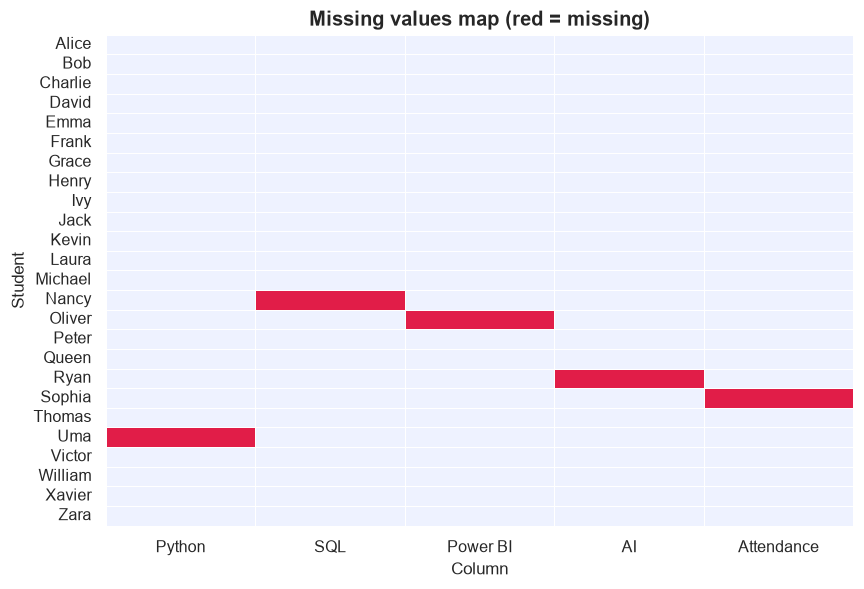

In [ ]:
missing_summary = pd.DataFrame({
    "Missing": raw_df.isna().sum(),
    "% Missing": (raw_df.isna().mean() * 100).round(1),
})
display(missing_summary)
print(f"Total missing cells: {int(raw_df.isna().sum().sum())}")
print("\nRows that contain missing values:")
display(raw_df[raw_df.isna().any(axis=1)])

fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(raw_df.set_index("Student")[SCORE_COLS].isna(), cbar=False, cmap=["#EEF2FF", "#E11D48"],
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("Missing values map (red = missing)")
ax.set_xlabel("Column"); ax.set_ylabel("Student")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/00_missing_values_map.png", bbox_inches="tight"); plt.show()

### 3.2 Zero value detection

In [ ]:
zero_mask = raw_df[SCORE_COLS].eq(0)
print("Zero values per column:")
display(zero_mask.sum().to_frame("Zeros"))
print("Rows containing zero values:")
display(raw_df[zero_mask.any(axis=1)])

Zero values per column:


,Zeros
Python,1
SQL,1
Power BI,0
AI,1
Attendance,1


Rows containing zero values:


,Student,Python,SQL,Power BI,AI,Attendance
12,Michael,0.0,82.0,80.0,78.0,88.0
15,Peter,69.0,71.0,74.0,0.0,86.0
22,William,79.0,0.0,76.0,78.0,91.0
24,Zara,82.0,85.0,84.0,86.0,0.0


### 3.3 Duplicate detection & removal

In [ ]:
exact_dupes = raw_df.duplicated()
name_dupes = raw_df["Student"].str.lower().duplicated(keep=False)
print(f"Exact duplicate rows : {int(exact_dupes.sum())}")
print(f"Repeated names       : {int(name_dupes.sum())}")
if name_dupes.any():
    display(raw_df[name_dupes])

dedup_df = (raw_df.drop_duplicates()
                  .drop_duplicates(subset="Student", keep="first")
                  .reset_index(drop=True))
print(f"Rows before: {len(raw_df)} -> rows after duplicate removal: {len(dedup_df)}")

Exact duplicate rows : 0
Repeated names       : 0
Rows before: 25 -> rows after duplicate removal: 25


### 3.4 Data validation

In [ ]:
def validate(df):
    """Run the data-quality checks and return a pass/fail table."""
    values = df[SCORE_COLS].stack()
    checks = {
        "Every row has a student name": df["Student"].notna().all(),
        "Student names are unique": df["Student"].is_unique,
        "Score columns are numeric": all(pd.api.types.is_numeric_dtype(df[c]) for c in SCORE_COLS),
        "All scores within 0-100": values.between(0, 100).all(),
        "No missing values": not df[SCORE_COLS].isna().any().any(),
        "No zero (invalid) values": not df[SCORE_COLS].eq(0).any().any(),
    }
    return pd.DataFrame({"Check": list(checks), "Passed": [bool(v) for v in checks.values()]})


def show_checks(table):
    return table.style.map(lambda v: "color:#059669;font-weight:600" if v is True
                           else "color:#DC2626;font-weight:600" if v is False else "", subset=["Passed"])

print("Validation of the RAW data:")
display(show_checks(validate(dedup_df)))

Validation of the RAW data:


,Check,Passed
0,Every row has a student name,True
1,Student names are unique,True
2,Score columns are numeric,True
3,All scores within 0-100,False
4,No missing values,False
5,No zero (invalid) values,False


### 3.5 Outlier detection (IQR method)

In [ ]:
def iqr_outliers(df, cols):
    """Return one row per value that falls outside the 1.5 x IQR fences."""
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        for _, r in df[(df[col] < lo) | (df[col] > hi)].iterrows():
            rows.append({"Student": r["Student"], "Column": col, "Value": r[col],
                         "Lower fence": round(lo, 1), "Upper fence": round(hi, 1)})
    return pd.DataFrame(rows, columns=["Student", "Column", "Value", "Lower fence", "Upper fence"])

raw_outliers = iqr_outliers(dedup_df, SCORE_COLS)
print(f"Outliers found in raw data: {len(raw_outliers)}")
display(raw_outliers)

Outliers found in raw data: 4


,Student,Column,Value,Lower fence,Upper fence
0,Michael,Python,0.0,54.5,108.5
1,William,SQL,0.0,55.8,103.8
2,Peter,AI,0.0,59.0,109.0
3,Zara,Attendance,0.0,79.0,105.0


### 3.6 Missing & zero value handling
| Problem | Decision | Reason |
|---|---|---|
| Missing **subject mark** | Use the student's own mean across their other valid subjects | It keeps each student at their own level. A class-wide median would pull strong and weak students towards the middle. |
| `0` **subject mark** | Treat as missing, then fill the same way | A 0 means absent or mis-typed, not a real score. Left in, it would wreck the student's average. |
| Missing / `0` **attendance** | Use the class median attendance | Attendance doesn't depend on subject marks, and the median isn't skewed by outliers. |

Every change goes into an **issue log**, so the processed dataset stays traceable.

In [ ]:
def build_issue_log(df):
    """List every missing, zero or out-of-range score in the raw data."""
    rows = []
    for _, r in df.iterrows():
        for col in SCORE_COLS:
            v = r[col]
            if pd.isna(v):
                issue = "Missing (Null)"
            elif v == 0:
                issue = "Zero value"
            elif not 0 <= v <= 100:
                issue = "Out of range"
            else:
                continue
            rows.append({"Student": r["Student"], "Column": col,
                         "Original": "Null" if pd.isna(v) else int(v), "Issue": issue})
    return pd.DataFrame(rows, columns=["Student", "Column", "Original", "Issue"])


def clean_scores(df):
    """Return a cleaned copy: invalid values -> NaN -> imputed, scores stored as int."""
    out = df.copy()
    scores = out[SCORE_COLS].mask(out[SCORE_COLS].eq(0))            # zeros are invalid
    scores = scores.where((scores >= 0) & (scores <= 100))          # anything outside 0-100 too
    student_mean = scores[SUBJECTS].mean(axis=1)
    for subject in SUBJECTS:
        scores[subject] = scores[subject].fillna(student_mean)
    scores["Attendance"] = scores["Attendance"].fillna(scores["Attendance"].median())
    out[SCORE_COLS] = scores.round(0).astype(int)
    return out


issue_log = build_issue_log(dedup_df)
clean_df = clean_scores(dedup_df)

issue_log["Imputed value"] = [int(clean_df.loc[clean_df["Student"] == s, c].iat[0])
                              for s, c in zip(issue_log["Student"], issue_log["Column"])]
issue_log["Method"] = np.where(issue_log["Column"] == "Attendance",
                               "Class median attendance", "Student's mean of valid subjects")
print(f"{len(issue_log)} values were corrected:")
display(issue_log)

9 values were corrected:


,Student,Column,Original,Issue,Imputed value,Method
0,Michael,Python,0,Zero value,80,Student's mean of valid subjects
1,Nancy,SQL,Null,Missing (Null),89,Student's mean of valid subjects
2,Oliver,Power BI,Null,Missing (Null),75,Student's mean of valid subjects
3,Peter,AI,0,Zero value,71,Student's mean of valid subjects
4,Ryan,AI,Null,Missing (Null),83,Student's mean of valid subjects
5,Sophia,Attendance,Null,Missing (Null),92,Class median attendance
6,Uma,Python,Null,Missing (Null),79,Student's mean of valid subjects
7,William,SQL,0,Zero value,78,Student's mean of valid subjects
8,Zara,Attendance,0,Zero value,92,Class median attendance


In [ ]:
affected = issue_log["Student"].unique()
before_after = dedup_df.set_index("Student").loc[affected, SCORE_COLS].merge(
    clean_df.set_index("Student").loc[affected, SCORE_COLS],
    left_index=True, right_index=True, suffixes=(" (raw)", " (clean)"))
before_after = before_after[[f"{c} ({k})" for c in SCORE_COLS for k in ("raw", "clean")]]
print("Before vs after for the affected students:")
display(before_after)

print("\nValidation of the CLEANED data:")
validation_clean = validate(clean_df)
display(show_checks(validation_clean))

Before vs after for the affected students:


,Python (raw),Python (clean),SQL (raw),SQL (clean),Power BI (raw),Power BI (clean),AI (raw),AI (clean),Attendance (raw),Attendance (clean)
Student,,,,,,,,,,
Michael,0.0,80,82.0,82,80.0,80,78.0,78,88.0,88
Nancy,87.0,87,NaN,89,89.0,89,91.0,91,95.0,95
Oliver,76.0,76,73.0,73,NaN,75,77.0,77,90.0,90
Peter,69.0,69,71.0,71,74.0,74,0.0,71,86.0,86
Ryan,81.0,81,84.0,84,83.0,83,NaN,83,92.0,92
Sophia,89.0,89,91.0,91,93.0,93,90.0,90,NaN,92
Uma,NaN,79,77.0,77,81.0,81,80.0,80,89.0,89
William,79.0,79,0.0,78,76.0,76,78.0,78,91.0,91
Zara,82.0,82,85.0,85,84.0,84,86.0,86,0.0,92



Validation of the CLEANED data:


,Check,Passed
0,Every row has a student name,True
1,Student names are unique,True
2,Score columns are numeric,True
3,All scores within 0-100,True
4,No missing values,True
5,No zero (invalid) values,True


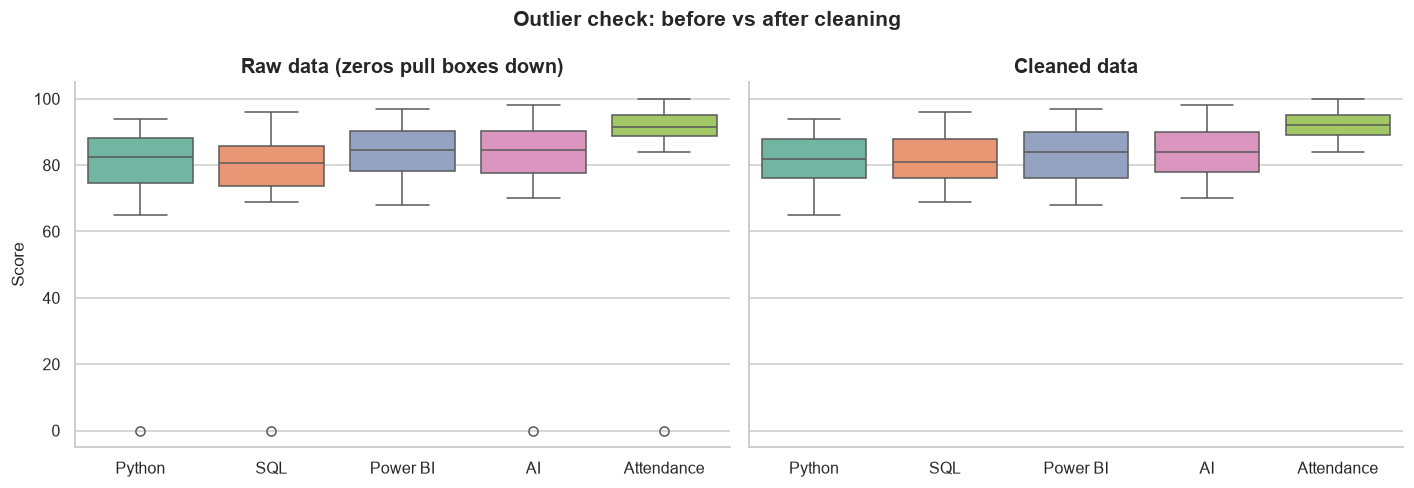

Outliers remaining after cleaning: 0


,Student,Column,Value,Lower fence,Upper fence


These are real (if unusual) results, so they stay in the data and are only flagged.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (title, frame) in zip(axes, [("Raw data (zeros pull boxes down)", dedup_df), ("Cleaned data", clean_df)]):
    long = frame.melt(id_vars="Student", value_vars=SCORE_COLS, var_name="Column", value_name="Score")
    sns.boxplot(data=long, x="Column", y="Score", hue="Column", palette="Set2", legend=False, ax=ax)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylabel("Score")
plt.suptitle("Outlier check: before vs after cleaning", fontweight="bold")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/01_outliers_before_after.png", bbox_inches="tight"); plt.show()

clean_outliers = iqr_outliers(clean_df, SCORE_COLS)
print(f"Outliers remaining after cleaning: {len(clean_outliers)}")
display(clean_outliers)
print("These are real (if unusual) results, so they stay in the data and are only flagged.")

## 4. Calculated Columns
| Column | Definition |
|---|---|
| **Total** | Sum of the four subject marks (out of 400) |
| **Average** | Mean of the four subject marks |
| **Grade** | A+ ≥ 90 · A ≥ 80 · B ≥ 70 · C ≥ 60 · D ≥ 50 · F < 50 (from Average) |
| **Rank** | 1 = highest Average. Ties share the same rank |
| **Best / Weakest Subject** | The student's highest / lowest subject |
| **Status** | `Needs Improvement` if Average < 75 or any subject < 70 |
| **Imputed** | Which values were corrected during cleaning |

In [ ]:
def assign_grade(avg):
    return next(grade for cutoff, grade in GRADE_BANDS if avg >= cutoff)


def add_features(df, issues):
    out = df.copy()
    out["Total"] = out[SUBJECTS].sum(axis=1)
    out["Average"] = out[SUBJECTS].mean(axis=1).round(2)
    out["Grade"] = out["Average"].apply(assign_grade)
    out["Rank"] = out["Average"].rank(ascending=False, method="min").astype(int)
    out["Best Subject"] = out[SUBJECTS].idxmax(axis=1)
    out["Weakest Subject"] = out[SUBJECTS].idxmin(axis=1)
    needs_help = (out["Average"] < NEEDS_HELP_AVG) | (out[SUBJECTS].min(axis=1) < NEEDS_HELP_SUBJECT)
    out["Status"] = np.where(needs_help, "Needs Improvement", "On Track")
    imputed = issues.groupby("Student")["Column"].apply(", ".join)
    out["Imputed"] = out["Student"].map(imputed).fillna("")
    return out


df = add_features(clean_df, issue_log)
ranked = df.sort_values(["Rank", "Student"]).reset_index(drop=True)
display(ranked)

,Student,Python,SQL,Power BI,AI,Attendance,Total,Average,Grade,Rank,Best Subject,Weakest Subject,Status,Imputed
0,Queen,94,96,95,98,100,383,95.75,A+,1,AI,Python,On Track,
1,Xavier,93,94,97,95,98,379,94.75,A+,2,Power BI,Python,On Track,
2,Grace,92,95,94,96,99,377,94.25,A+,3,AI,Python,On Track,
3,Sophia,89,91,93,90,92,363,90.75,A+,4,Power BI,Python,On Track,Attendance
4,Kevin,91,88,90,92,96,361,90.25,A+,5,AI,SQL,On Track,
5,Emma,88,90,91,89,97,358,89.50,A,6,Power BI,Python,On Track,
6,Nancy,87,89,89,91,95,356,89.00,A,7,AI,Python,On Track,SQL
7,Charlie,90,85,87,93,98,355,88.75,A,8,AI,SQL,On Track,
8,Victor,86,83,88,87,94,344,86.00,A,9,Power BI,SQL,On Track,
9,Alice,85,78,92,88,95,343,85.75,A,10,Power BI,SQL,On Track,


## 5. Descriptive Statistics

In [ ]:
stats = df[SCORE_COLS + ["Total", "Average"]].describe().T
stats["median"] = df[SCORE_COLS + ["Total", "Average"]].median()
stats["skew"] = df[SCORE_COLS + ["Total", "Average"]].skew()
display(stats.round(2))

print("Grade distribution:")
display(df["Grade"].value_counts().reindex(GRADE_ORDER, fill_value=0).to_frame("Students").T)

,count,mean,std,min,25%,50%,75%,max,median,skew
Python,25.0,81.60,8.13,65.00,76.0,82.00,88.0,94.00,82.00,-0.34
SQL,25.0,81.60,8.02,69.00,76.0,81.00,88.0,96.00,81.00,0.21
Power BI,25.0,83.44,8.28,68.00,76.0,84.00,90.0,97.00,84.00,-0.20
AI,25.0,83.76,8.11,70.00,78.0,84.00,90.0,98.00,84.00,-0.01
Attendance,25.0,92.20,4.43,84.00,89.0,92.00,95.0,100.00,92.00,-0.04
Total,25.0,330.40,31.50,275.00,308.0,331.00,356.0,383.00,331.00,-0.04
Average,25.0,82.60,7.88,68.75,77.0,82.75,89.0,95.75,82.75,-0.04


Grade distribution:


Grade,A+,A,B,C,D,F
Students,5,10,9,1,0,0


## 6. Dashboard Overview: KPI Cards

In [ ]:
top_row = ranked.iloc[0]
low_row = ranked.iloc[-1]
kpis = {
    "total_students": int(len(df)),
    "avg_attendance": round(float(df["Attendance"].mean()), 2),
    "highest_avg": float(top_row["Average"]),
    "highest_name": str(top_row["Student"]),
    "lowest_avg": float(low_row["Average"]),
    "lowest_name": str(low_row["Student"]),
    "class_avg": round(float(df["Average"].mean()), 2),
    "above_85": int((df["Average"] > HIGH_SCORE).sum()),
    "below_60": int((df["Average"] < LOW_SCORE).sum()),
}

KPI_CARDS = [
    ("👥", "Total Students", kpis["total_students"], "enrolled", "#4F46E5"),
    ("📅", "Average Attendance", f"{kpis['avg_attendance']:.1f}%", "across the class", "#0EA5A4"),
    ("🏆", "Highest Average", f"{kpis['highest_avg']:.2f}", kpis["highest_name"], "#059669"),
    ("📉", "Lowest Average", f"{kpis['lowest_avg']:.2f}", kpis["lowest_name"], "#E11D48"),
    ("📊", "Class Average", f"{kpis['class_avg']:.2f}", "all subjects", "#F59E0B"),
    ("⭐", f"Above {HIGH_SCORE}%", kpis["above_85"], "students", "#7C3AED"),
    ("⚠️", f"Below {LOW_SCORE}%", kpis["below_60"], "students", "#DC2626"),
]

def kpi_html(cards):
    items = "".join(
        f"""<div style="flex:1 1 170px;background:#fff;border:1px solid #E5E7EB;border-top:4px solid {color};
                   border-radius:12px;padding:14px 16px;box-shadow:0 1px 3px rgba(0,0,0,.06)">
              <div style="font-size:13px;color:#6B7280">{icon} {label}</div>
              <div style="font-size:26px;font-weight:700;color:#111827;margin:4px 0">{value}</div>
              <div style="font-size:12px;color:#6B7280">{sub}</div></div>"""
        for icon, label, value, sub, color in cards)
    return f'<div style="display:flex;flex-wrap:wrap;gap:12px;font-family:Segoe UI,Roboto,sans-serif">{items}</div>'

display(HTML(kpi_html(KPI_CARDS)))

## 7. Student Analysis
### 7.1 Rankings (class topper highlighted in gold, lowest performer in red)

In [ ]:
def highlight_extremes(row):
    if row["Rank"] == ranked["Rank"].min():
        return ["background-color:#FEF3C7;font-weight:600"] * len(row)
    if row["Average"] == ranked["Average"].min():
        return ["background-color:#FEE2E2"] * len(row)
    return [""] * len(row)

rank_cols = ["Rank", "Student", *SUBJECTS, "Total", "Average", "Grade", "Attendance", "Status"]
display(ranked[rank_cols].style
        .apply(highlight_extremes, axis=1)
        .background_gradient(subset=["Average"], cmap="Blues")
        .bar(subset=["Attendance"], color="#A7F3D0", vmin=80, vmax=100)
        .format({"Average": "{:.2f}"})
        .hide(axis="index"))

Rank,Student,Python,SQL,Power BI,AI,Total,Average,Grade,Attendance,Status
1,Queen,94,96,95,98,383,95.75,A+,100,On Track
2,Xavier,93,94,97,95,379,94.75,A+,98,On Track
3,Grace,92,95,94,96,377,94.25,A+,99,On Track
4,Sophia,89,91,93,90,363,90.75,A+,92,On Track
5,Kevin,91,88,90,92,361,90.25,A+,96,On Track
6,Emma,88,90,91,89,358,89.50,A,97,On Track
7,Nancy,87,89,89,91,356,89.00,A,95,On Track
8,Charlie,90,85,87,93,355,88.75,A,98,On Track
9,Victor,86,83,88,87,344,86.00,A,94,On Track
10,Alice,85,78,92,88,343,85.75,A,95,On Track


### 7.2 Class topper & lowest-performing student

In [ ]:
def profile_card(row, title, color):
    marks = " · ".join(f"{s}: <b>{row[s]}</b>" for s in SUBJECTS)
    return f"""<div style="flex:1 1 320px;border-left:6px solid {color};background:#F9FAFB;border-radius:10px;padding:14px 18px;font-family:Segoe UI,sans-serif">
      <div style="font-size:12px;letter-spacing:.06em;color:{color};font-weight:700">{title}</div>
      <div style="font-size:22px;font-weight:700;margin:2px 0">{row['Student']}</div>
      <div>Average <b>{row['Average']:.2f}</b> · Total <b>{row['Total']}</b>/400 · Grade <b>{row['Grade']}</b> · Rank <b>#{row['Rank']}</b></div>
      <div style="margin-top:4px">{marks}</div>
      <div style="margin-top:4px;color:#6B7280">Attendance {row['Attendance']}% · Best: {row['Best Subject']} · Weakest: {row['Weakest Subject']}</div></div>"""

display(HTML('<div style="display:flex;gap:14px;flex-wrap:wrap">'
             + profile_card(top_row, "🏆 CLASS TOPPER", "#D97706")
             + profile_card(low_row, "📉 NEEDS THE MOST SUPPORT", "#DC2626") + "</div>"))

### 7.3 Complete information for a student

In [ ]:
def student_report(name):
    """Every field for one student, plus how they compare with the class average."""
    row = df.loc[df["Student"].str.lower() == name.strip().lower()]
    if row.empty:
        raise ValueError(f"No student called '{name}'. Options: {', '.join(sorted(df['Student']))}")
    r = row.iloc[0]
    detail = pd.DataFrame({
        "Student": [r[c] for c in SCORE_COLS],
        "Class average": [round(df[c].mean(), 2) for c in SCORE_COLS],
    }, index=SCORE_COLS)
    detail["Difference"] = (detail["Student"] - detail["Class average"]).round(2)
    display(HTML(profile_card(r, "STUDENT PROFILE", "#4F46E5")))
    display(detail)
    if r["Imputed"]:
        print(f"Note: imputed during cleaning -> {r['Imputed']}")

student_report("Michael")

,Student,Class average,Difference
Python,80,81.60,-1.60
SQL,82,81.60,0.40
Power BI,80,83.44,-3.44
AI,78,83.76,-5.76
Attendance,88,92.20,-4.20


Note: imputed during cleaning -> Python


### 7.4 Compare students

In [ ]:
def compare_students(names):
    cols = SCORE_COLS + ["Total", "Average"]
    table = df.set_index("Student").loc[names, cols].T
    table["Class avg"] = df[cols].mean().round(2)
    return table

display(compare_students(["Queen", "Xavier", "Grace", "David"]))

Student,Queen,Xavier,Grace,David,Class avg
Python,94.00,93.00,92.00,65.00,81.60
SQL,96.00,94.00,95.00,70.00,81.60
Power BI,95.00,97.00,94.00,68.00,83.44
AI,98.00,95.00,96.00,72.00,83.76
Attendance,100.00,98.00,99.00,85.00,92.20
Total,383.00,379.00,377.00,275.00,330.40
Average,95.75,94.75,94.25,68.75,82.60


### 7.5 Filter students by marks or attendance

In [ ]:
def filter_students(min_avg=0, max_avg=100, min_attendance=0, subject=None, min_subject=0, grade=None, search=""):
    mask = df["Average"].between(min_avg, max_avg) & (df["Attendance"] >= min_attendance)
    if subject:
        mask &= df[subject] >= min_subject
    if grade:
        mask &= df["Grade"] == grade
    if search:
        mask &= df["Student"].str.contains(search, case=False, regex=False)
    return df.loc[mask, rank_cols].sort_values("Rank")

print("Average >= 85 and attendance >= 95%:")
display(filter_students(min_avg=85, min_attendance=95))
print("Scored at least 90 in AI:")
display(filter_students(subject="AI", min_subject=90))

Average >= 85 and attendance >= 95%:


,Rank,Student,Python,SQL,Power BI,AI,Total,Average,Grade,Attendance,Status
16,1,Queen,94,96,95,98,383,95.75,A+,100,On Track
23,2,Xavier,93,94,97,95,379,94.75,A+,98,On Track
6,3,Grace,92,95,94,96,377,94.25,A+,99,On Track
10,5,Kevin,91,88,90,92,361,90.25,A+,96,On Track
4,6,Emma,88,90,91,89,358,89.50,A,97,On Track
13,7,Nancy,87,89,89,91,356,89.00,A,95,On Track
2,8,Charlie,90,85,87,93,355,88.75,A,98,On Track
0,10,Alice,85,78,92,88,343,85.75,A,95,On Track


Scored at least 90 in AI:


,Rank,Student,Python,SQL,Power BI,AI,Total,Average,Grade,Attendance,Status
16,1,Queen,94,96,95,98,383,95.75,A+,100,On Track
23,2,Xavier,93,94,97,95,379,94.75,A+,98,On Track
6,3,Grace,92,95,94,96,377,94.25,A+,99,On Track
18,4,Sophia,89,91,93,90,363,90.75,A+,92,On Track
10,5,Kevin,91,88,90,92,361,90.25,A+,96,On Track
13,7,Nancy,87,89,89,91,356,89.00,A,95,On Track
2,8,Charlie,90,85,87,93,355,88.75,A,98,On Track


## 8. Data Visualizations
**8.1–8.7 use Matplotlib & Seaborn** (static charts, saved as PNG in `charts/`).
**8.8–8.13 use Plotly**: hover for tooltips, drag to zoom, double-click to reset, and use the camera icon to save a PNG.
**8.14 uses Altair** for linked brushing.

### 8.1 Bar chart: subject-wise average (Matplotlib)

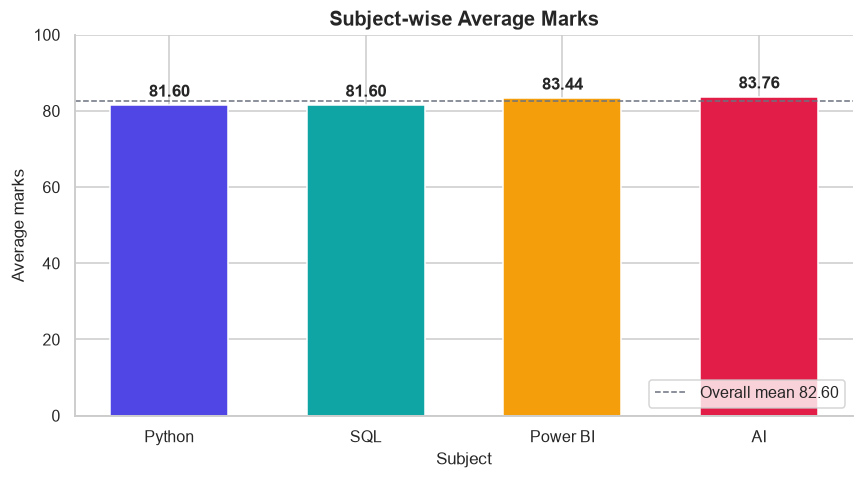

In [ ]:
subject_avg = df[SUBJECTS].mean().round(2)
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(SUBJECTS, subject_avg, color=[SUBJECT_COLORS[s] for s in SUBJECTS], width=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3, fontweight="bold")
ax.axhline(subject_avg.mean(), ls="--", color="#6B7280", lw=1, label=f"Overall mean {subject_avg.mean():.2f}")
ax.set_ylim(0, 100); ax.set_title("Subject-wise Average Marks"); ax.set_xlabel("Subject"); ax.set_ylabel("Average marks")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/02_subject_average_bar.png", bbox_inches="tight"); plt.show()

### 8.2 Histogram: distribution of averages (Seaborn)

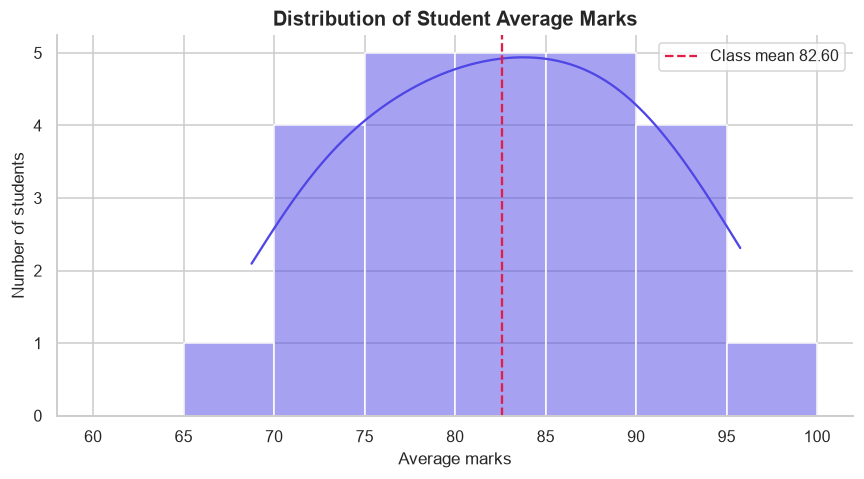

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["Average"], bins=range(60, 101, 5), kde=True, color="#4F46E5", edgecolor="white", ax=ax)
ax.axvline(df["Average"].mean(), color="#E11D48", ls="--", label=f"Class mean {df['Average'].mean():.2f}")
ax.set_title("Distribution of Student Average Marks"); ax.set_xlabel("Average marks"); ax.set_ylabel("Number of students")
ax.legend()
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/03_average_histogram.png", bbox_inches="tight"); plt.show()

### 8.3 Line chart: subject marks across students ordered by rank (Matplotlib)

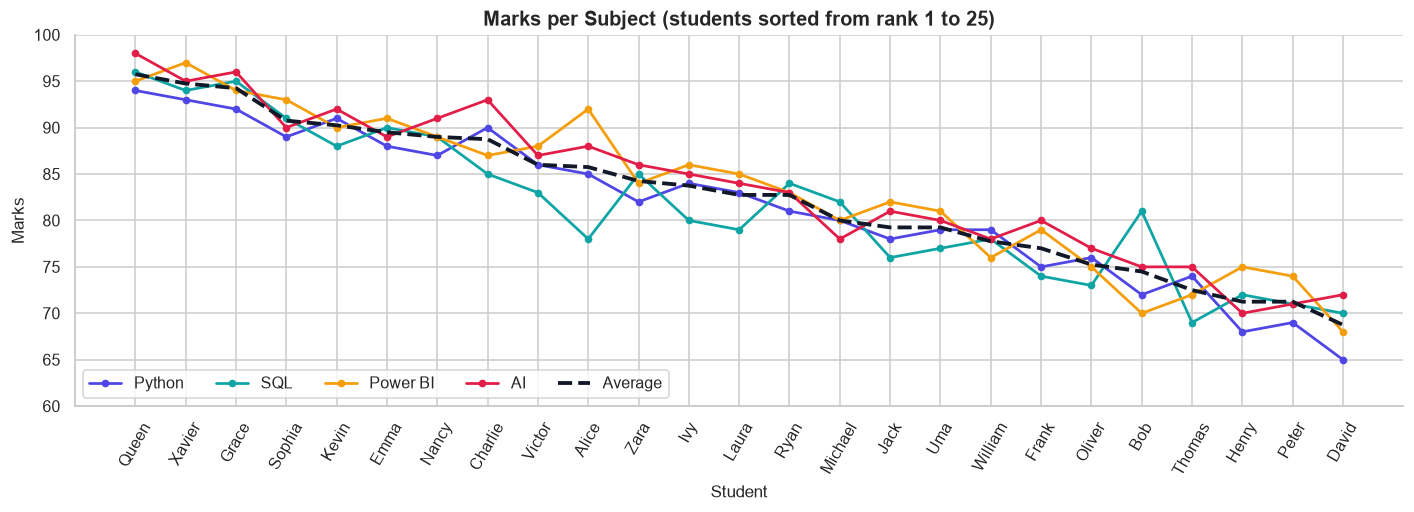

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4.8))
for s in SUBJECTS:
    ax.plot(ranked["Student"], ranked[s], marker="o", ms=4, lw=1.8, label=s, color=SUBJECT_COLORS[s])
ax.plot(ranked["Student"], ranked["Average"], color="#111827", lw=2.5, ls="--", label="Average")
ax.set_title("Marks per Subject (students sorted from rank 1 to 25)")
ax.set_xlabel("Student"); ax.set_ylabel("Marks"); ax.set_ylim(60, 100)
ax.tick_params(axis="x", rotation=60); ax.legend(ncol=5, loc="lower left")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/04_marks_line_chart.png", bbox_inches="tight"); plt.show()

### 8.4 Pie chart: grade distribution (Matplotlib)

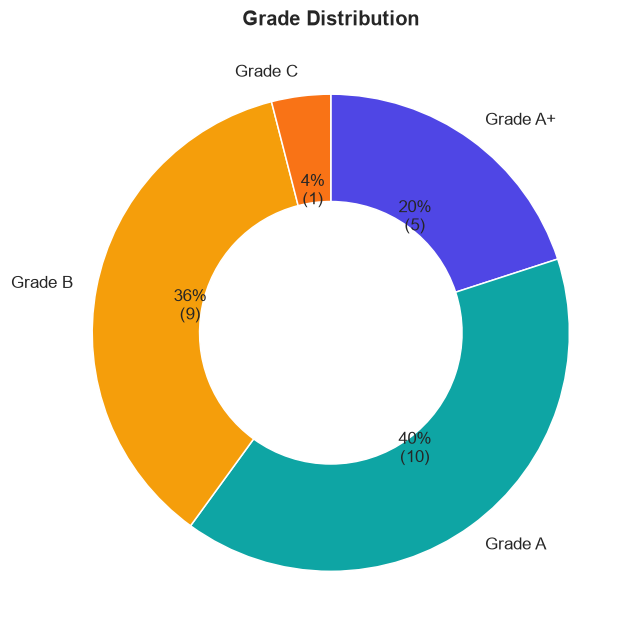

In [ ]:
grade_counts = df["Grade"].value_counts().reindex(GRADE_ORDER).dropna().astype(int)
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(grade_counts, labels=[f"Grade {g}" for g in grade_counts.index],
       autopct=lambda p: f"{p:.0f}%\n({round(p * len(df) / 100)})",
       colors=[GRADE_COLORS[g] for g in grade_counts.index], startangle=90, counterclock=False,
       wedgeprops={"width": 0.45, "edgecolor": "white"}, textprops={"fontsize": 11})
ax.set_title("Grade Distribution")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/05_grade_pie.png", bbox_inches="tight"); plt.show()

### 8.5 Box plot: spread of marks per subject (Seaborn)

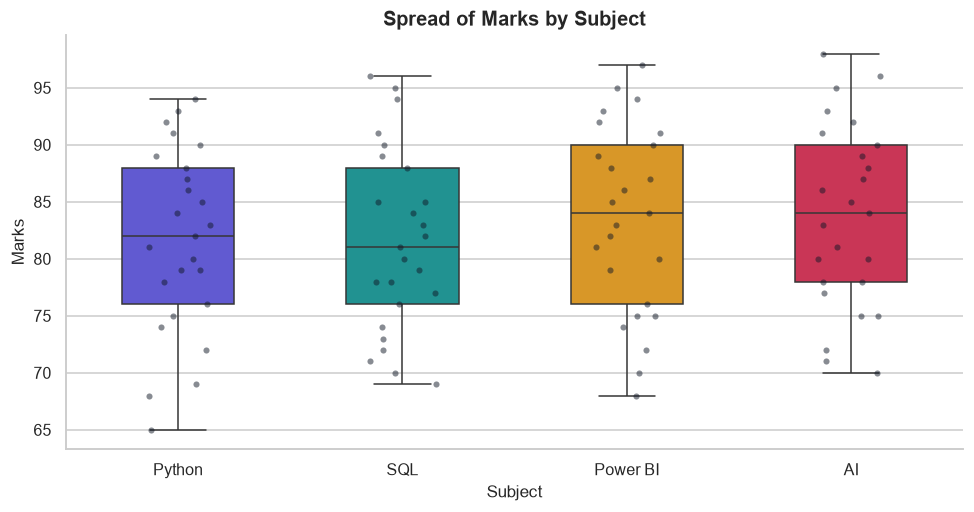

In [ ]:
long_df = df.melt(id_vars=["Student", "Grade"], value_vars=SUBJECTS, var_name="Subject", value_name="Marks")
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(data=long_df, x="Subject", y="Marks", hue="Subject", palette=SUBJECT_COLORS, width=0.5, legend=False, ax=ax)
sns.stripplot(data=long_df, x="Subject", y="Marks", color="#111827", size=4, alpha=0.5, jitter=0.15, ax=ax)
ax.set_title("Spread of Marks by Subject")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/06_subject_boxplot.png", bbox_inches="tight"); plt.show()

### 8.6 Heatmaps: correlation matrix & marks matrix (Seaborn)

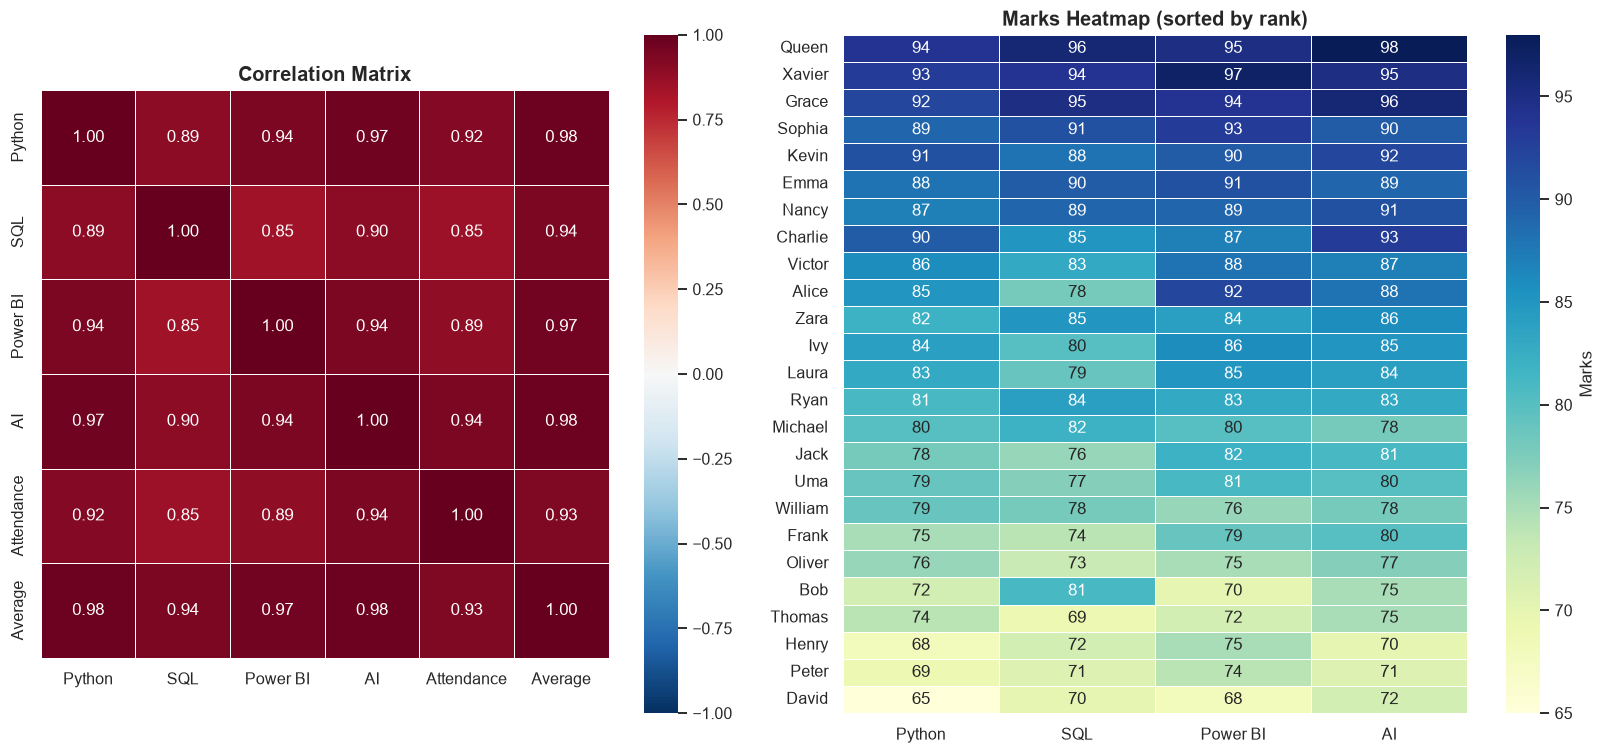

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [1, 1.1]})
corr = df[SCORE_COLS + ["Average"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=axes[0])
axes[0].set_title("Correlation Matrix")
sns.heatmap(ranked.set_index("Student")[SUBJECTS], annot=True, fmt="d", cmap="YlGnBu", linewidths=0.4,
            cbar_kws={"label": "Marks"}, ax=axes[1])
axes[1].set_title("Marks Heatmap (sorted by rank)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/07_heatmaps.png", bbox_inches="tight"); plt.show()

### 8.7 Attendance vs performance: regression plot (Seaborn)

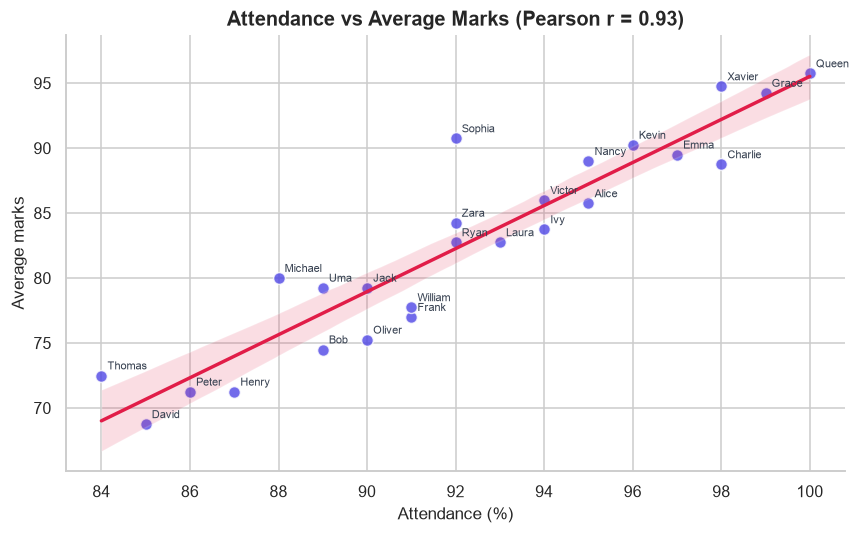

In [ ]:
att_corr = df["Attendance"].corr(df["Average"])
fig, ax = plt.subplots(figsize=(8, 5))
sns.regplot(data=df, x="Attendance", y="Average", ax=ax, color="#4F46E5",
            scatter_kws={"s": 60, "edgecolor": "white"}, line_kws={"color": "#E11D48"})
for _, r in df.iterrows():
    ax.annotate(r["Student"], (r["Attendance"], r["Average"]), textcoords="offset points", xytext=(4, 4),
                fontsize=7.5, color="#374151")
ax.set_title(f"Attendance vs Average Marks (Pearson r = {att_corr:.2f})")
ax.set_xlabel("Attendance (%)"); ax.set_ylabel("Average marks")
plt.tight_layout(); plt.savefig(f"{CHART_DIR}/08_attendance_vs_average.png", bbox_inches="tight"); plt.show()

### 8.8 Bubble chart: attendance vs average, bubble size = total (Plotly)

In [ ]:
fig = px.scatter(df, x="Attendance", y="Average", size="Total", color="Grade", text="Student",
                 color_discrete_map=GRADE_COLORS, category_orders={"Grade": GRADE_ORDER}, size_max=28,
                 hover_data={"Rank": True, "Total": True, "Python": True, "SQL": True, "Power BI": True, "AI": True},
                 title="Attendance vs Average Marks (bubble size = total marks)")
slope, intercept = np.polyfit(df["Attendance"], df["Average"], 1)
xs = np.array([df["Attendance"].min(), df["Attendance"].max()])
fig.add_trace(go.Scatter(x=xs, y=slope * xs + intercept, mode="lines", name="Trend",
                         line=dict(dash="dash", color="#6B7280")))
fig.add_annotation(x=top_row["Attendance"], y=top_row["Average"], text=f"🏆 Topper: {top_row['Student']}",
                   showarrow=True, arrowhead=2, ax=-70, ay=-35)
fig.update_traces(textposition="top center", textfont_size=9, selector=dict(mode="markers+text"))
fig.update_layout(xaxis_title="Attendance (%)", yaxis_title="Average marks", height=520, legend_title="Grade")
fig.write_html(f"{CHART_DIR}/09_bubble_chart.html", include_plotlyjs="cdn")
fig.show()

### 8.9 Grouped bar chart with zoom & range slider (Plotly)

In [ ]:
fig = go.Figure()
for s in SUBJECTS:
    fig.add_bar(name=s, x=ranked["Student"], y=ranked[s], marker_color=SUBJECT_COLORS[s],
                hovertemplate="%{x}<br>" + s + ": %{y}<extra></extra>")
fig.add_scatter(name="Average", x=ranked["Student"], y=ranked["Average"], mode="lines+markers",
                line=dict(color="#111827", width=2))
fig.update_layout(barmode="group", title="Marks by Student and Subject (drag the slider to zoom)",
                  xaxis=dict(title="Student", rangeslider=dict(visible=True), range=[-0.5, 9.5]),
                  yaxis=dict(title="Marks", range=[50, 100]), height=520, legend_title="Subject")
fig.write_html(f"{CHART_DIR}/10_grouped_bar_zoom.html", include_plotlyjs="cdn")
fig.show()

### 8.10 Area chart: stacked subject marks by rank (Plotly)

In [ ]:
fig = go.Figure()
for s in SUBJECTS:
    fig.add_scatter(x=ranked["Student"], y=ranked[s], name=s, mode="lines", stackgroup="one",
                    line=dict(width=0.8, color=SUBJECT_COLORS[s]), hovertemplate="%{x}<br>" + s + ": %{y}<extra></extra>")
fig.update_layout(title="Total Marks Composition by Student (stacked area)", xaxis_title="Student (rank order)",
                  yaxis_title="Total marks (out of 400)", hovermode="x unified", height=460)
fig.write_html(f"{CHART_DIR}/11_area_chart.html", include_plotlyjs="cdn")
fig.show()

### 8.11 Sunburst & 8.12 Treemap: grade → student hierarchy (Plotly)

In [ ]:
fig = px.sunburst(df, path=["Grade", "Student"], values="Total", color="Grade", color_discrete_map=GRADE_COLORS,
                  hover_data={"Average": ":.2f"}, title="Sunburst: Grade → Student (size = total marks)")
fig.update_layout(height=560)
fig.write_html(f"{CHART_DIR}/12_sunburst.html", include_plotlyjs="cdn")
fig.show()

fig = px.treemap(df, path=[px.Constant("Class"), "Grade", "Student"], values="Total", color="Average",
                 color_continuous_scale="Tealgrn", hover_data={"Attendance": True},
                 title="Treemap: Students grouped by Grade (colour = average)")
fig.update_layout(height=520)
fig.write_html(f"{CHART_DIR}/13_treemap.html", include_plotlyjs="cdn")
fig.show()

### 8.13 Radar chart: topper vs lowest performer vs class average (Plotly)

In [ ]:
def radar_figure(names, title="Subject Profile"):
    cats = SUBJECTS + [SUBJECTS[0]]
    fig = go.Figure()
    fig.add_trace(go.Scatterpolar(r=[df[s].mean() for s in cats], theta=cats, name="Class average",
                                  line=dict(color="#9CA3AF", dash="dash")))
    colors = ["#4F46E5", "#E11D48", "#0EA5A4", "#F59E0B", "#7C3AED"]
    for name, color in zip(names, colors):
        row = df.set_index("Student").loc[name]
        fig.add_trace(go.Scatterpolar(r=[row[s] for s in cats], theta=cats, name=name, fill="toself",
                                      opacity=0.55, line=dict(color=color)))
    fig.update_layout(title=title, polar=dict(radialaxis=dict(range=[50, 100])), height=480)
    return fig

fig = radar_figure([top_row["Student"], low_row["Student"]], "Topper vs Lowest Performer vs Class Average")
fig.write_html(f"{CHART_DIR}/14_radar.html", include_plotlyjs="cdn")
fig.show()

### 8.14 Linked brushing (Altair)
Drag across the scatter plot to select students. The bar chart then shows only your selection.

In [ ]:
alt_df = df[["Student", "Attendance", "Average", "Grade", "Total"]]
brush = alt.selection_interval(encodings=["x", "y"])
grade_scale = alt.Scale(domain=GRADE_ORDER, range=[GRADE_COLORS[g] for g in GRADE_ORDER])

scatter = (alt.Chart(alt_df).mark_circle(size=110, opacity=0.85)
           .encode(x=alt.X("Attendance:Q", scale=alt.Scale(zero=False), title="Attendance (%)"),
                   y=alt.Y("Average:Q", scale=alt.Scale(zero=False), title="Average marks"),
                   color=alt.condition(brush, alt.Color("Grade:N", scale=grade_scale), alt.value("#D1D5DB")),
                   tooltip=["Student", "Attendance", "Average", "Grade", "Total"])
           .add_params(brush)
           .properties(width=420, height=320, title="Drag to select students"))

bars = (alt.Chart(alt_df).mark_bar()
        .encode(y=alt.Y("Student:N", sort="-x", title=None), x=alt.X("Average:Q", title="Average marks"),
                color=alt.Color("Grade:N", scale=grade_scale), tooltip=["Student", "Average"])
        .transform_filter(brush)
        .properties(width=300, height=320, title="Selected students"))

alt.hconcat(scatter, bars).configure_title(fontSize=14, anchor="start")

alt.HConcatChart(...)

## 9. Interactive Dashboard (ipywidgets)
> These widgets are live in **Colab** or **Jupyter**: change a control and the output updates straight away. A notebook viewed on GitHub only shows the last output.

### 9.1 Student explorer: pick a student from the dropdown

In [ ]:
student_dd = widgets.Dropdown(options=sorted(df["Student"]), value=top_row["Student"], description="Student:",
                              layout=widgets.Layout(width="280px"))
explorer_out = widgets.Output()

def render_student(change=None):
    name = student_dd.value
    r = df.set_index("Student").loc[name]
    with explorer_out:
        explorer_out.clear_output(wait=True)
        badge = " 🏆 <b style='color:#D97706'>CLASS TOPPER</b>" if r["Rank"] == 1 else ""
        display(HTML(f"<h3 style='margin:4px 0'>{name}{badge}</h3>"
                     f"Rank <b>#{r['Rank']}</b> of {len(df)} · Average <b>{r['Average']:.2f}</b> · "
                     f"Total <b>{r['Total']}</b> · Grade <b>{r['Grade']}</b> · Attendance <b>{r['Attendance']}%</b> · {r['Status']}"))
        fig = go.Figure()
        fig.add_bar(x=SUBJECTS, y=[r[s] for s in SUBJECTS], name=name, marker_color=[SUBJECT_COLORS[s] for s in SUBJECTS],
                    text=[r[s] for s in SUBJECTS], textposition="outside")
        fig.add_scatter(x=SUBJECTS, y=[df[s].mean() for s in SUBJECTS], name="Class average", mode="lines+markers",
                        line=dict(color="#111827", dash="dash"))
        fig.update_layout(title=f"{name}: marks vs class average", yaxis=dict(range=[0, 105], title="Marks"),
                          xaxis_title="Subject", height=380, margin=dict(t=50, b=40))
        fig.show()
        att = go.Figure()
        att.add_bar(y=["Attendance %", "Average marks"], x=[r["Attendance"], r["Average"]], orientation="h",
                    name=name, marker_color="#4F46E5")
        att.add_bar(y=["Attendance %", "Average marks"], x=[df["Attendance"].mean(), df["Average"].mean()],
                    orientation="h", name="Class average", marker_color="#CBD5E1")
        att.update_layout(title="Attendance compared with average marks", barmode="group", xaxis=dict(range=[0, 100]),
                          height=260, margin=dict(t=50, b=30))
        att.show()

student_dd.observe(render_student, names="value")
render_student()
display(student_dd, explorer_out)

Dropdown(description='Student:', index=16, layout=Layout(width='280px'), options=('Alice', 'Bob', 'Charlie', '…

Output()

### 9.2 Compare students: select two or more (Ctrl/Cmd + click), then choose subjects

In [ ]:
compare_sel = widgets.SelectMultiple(options=sorted(df["Student"]), value=("Queen", "David", "Michael"),
                                     description="Students:", rows=8, layout=widgets.Layout(width="260px"))
subject_sel = widgets.SelectMultiple(options=SUBJECTS, value=tuple(SUBJECTS), description="Subjects:", rows=4,
                                     layout=widgets.Layout(width="240px"))
compare_out = widgets.Output()

def render_compare(change=None):
    names, subs = list(compare_sel.value), list(subject_sel.value)
    with compare_out:
        compare_out.clear_output(wait=True)
        if not names or not subs:
            print("Select at least one student and one subject.")
            return
        sub_df = (df.set_index("Student").loc[names, subs].reset_index()
                    .melt(id_vars="Student", var_name="Subject", value_name="Marks"))
        fig = px.bar(sub_df, x="Subject", y="Marks", color="Student", barmode="group", text="Marks",
                     title="Student comparison", range_y=[0, 105])
        fig.update_layout(height=400)
        fig.show()
        radar_figure(names[:5], "Subject profile (all subjects)").show()

for w in (compare_sel, subject_sel):
    w.observe(render_compare, names="value")
render_compare()
display(widgets.HBox([compare_sel, subject_sel]), compare_out)

Output()

### 9.3 Search, filter & sort: the table and chart update as you type

In [ ]:
search_box = widgets.Text(placeholder="Search student…", description="Search:", layout=widgets.Layout(width="260px"))
avg_slider = widgets.FloatRangeSlider(value=(60, 100), min=60, max=100, step=0.5, description="Average:",
                                      readout_format=".1f", layout=widgets.Layout(width="380px"))
att_slider = widgets.IntSlider(value=80, min=80, max=100, description="Min attend.:", layout=widgets.Layout(width="320px"))
grade_dd = widgets.Dropdown(options=["All"] + GRADE_ORDER, value="All", description="Grade:",
                            layout=widgets.Layout(width="180px"))
metric_dd = widgets.Dropdown(options=["Average"] + SUBJECTS + ["Attendance"], value="Average", description="Chart by:",
                             layout=widgets.Layout(width="220px"))
sort_dd = widgets.Dropdown(options=["Rank", "Student", "Average", "Total", "Attendance"] + SUBJECTS, value="Rank",
                           description="Sort by:", layout=widgets.Layout(width="220px"))
asc_tg = widgets.ToggleButtons(options=["Ascending", "Descending"], value="Ascending", style={"button_width": "95px"})
filter_out = widgets.Output()

def render_filtered(change=None):
    view = filter_students(min_avg=avg_slider.value[0], max_avg=avg_slider.value[1], min_attendance=att_slider.value,
                           grade=None if grade_dd.value == "All" else grade_dd.value, search=search_box.value)
    view = view.sort_values(sort_dd.value, ascending=asc_tg.value == "Ascending")
    with filter_out:
        filter_out.clear_output(wait=True)
        print(f"Showing {len(view)} of {len(df)} students")
        if view.empty:
            return
        display(view.style.apply(highlight_extremes, axis=1).format({"Average": "{:.2f}"}).hide(axis="index"))
        metric = metric_dd.value
        colors = ["#D97706" if r == 1 else "#4F46E5" for r in view["Rank"]]
        fig = go.Figure(go.Bar(x=view["Student"], y=view[metric], marker_color=colors, text=view[metric],
                               textposition="outside", hovertemplate="%{x}<br>" + metric + ": %{y}<extra></extra>"))
        fig.update_layout(title=f"{metric} for the filtered students (gold = topper)",
                          yaxis=dict(range=[0, 105], title=metric), xaxis_title="Student", height=380, margin=dict(t=50))
        fig.show()

for w in (search_box, avg_slider, att_slider, grade_dd, metric_dd, sort_dd, asc_tg):
    w.observe(render_filtered, names="value")
render_filtered()
display(widgets.VBox([widgets.HBox([search_box, grade_dd, metric_dd]),
                      widgets.HBox([avg_slider, att_slider]),
                      widgets.HBox([sort_dd, asc_tg])]), filter_out)

Output()

## 10. Performance Insights

In [ ]:
top5 = ranked.head(5)[["Rank", "Student", "Average", "Grade", "Attendance"]]
bottom5 = ranked.tail(5).iloc[::-1][["Rank", "Student", "Average", "Grade", "Attendance"]]
display(HTML("<h4>🥇 Top 5 performers</h4>")); display(top5.style.hide(axis="index").format({"Average": "{:.2f}"}))
display(HTML("<h4>📉 Bottom 5 performers (lowest first)</h4>")); display(bottom5.style.hide(axis="index").format({"Average": "{:.2f}"}))

Rank,Student,Average,Grade,Attendance
1,Queen,95.75,A+,100
2,Xavier,94.75,A+,98
3,Grace,94.25,A+,99
4,Sophia,90.75,A+,92
5,Kevin,90.25,A+,96


Rank,Student,Average,Grade,Attendance
25,David,68.75,C,85
23,Peter,71.25,B,86
23,Henry,71.25,B,87
22,Thomas,72.50,B,84
21,Bob,74.50,B,89


In [ ]:
subject_summary = pd.DataFrame({
    "Average": df[SUBJECTS].mean().round(2),
    "Highest": df[SUBJECTS].max(),
    "Lowest": df[SUBJECTS].min(),
    "Std dev": df[SUBJECTS].std().round(2),
    "Corr. with attendance": [round(df[s].corr(df["Attendance"]), 2) for s in SUBJECTS],
    "Top scorer": [df.loc[df[s].idxmax(), "Student"] for s in SUBJECTS],
}).sort_values("Average", ascending=False)
display(HTML("<h4>📚 Subject-wise summary</h4>")); display(subject_summary)

best_subject, worst_subject = subject_summary.index[0], subject_summary.index[-1]

att_bands = pd.cut(df["Attendance"], bins=[0, 89, 94, 100], labels=["< 90%", "90–94%", "95–100%"])
att_table = (df.groupby(att_bands, observed=True)
               .agg(Students=("Student", "count"), Avg_marks=("Average", "mean")).round(2))
display(HTML("<h4>📅 Attendance vs performance</h4>")); display(att_table)
print(f"Pearson correlation between attendance and average marks: r = {att_corr:.2f}")

perfect = df.loc[df["Attendance"] == 100, "Student"].tolist()
needs_help = ranked.loc[ranked["Status"] == "Needs Improvement", ["Student", "Average", "Weakest Subject", "Attendance"]]
needs_help = needs_help.assign(**{"Weakest mark": [df.set_index("Student").loc[n, s]
                                                   for n, s in zip(needs_help["Student"], needs_help["Weakest Subject"])]})
display(HTML(f"<h4>🎯 Students with perfect attendance</h4><p>{', '.join(perfect) or 'None'}</p>"))
display(HTML(f"<h4>🛠️ Students requiring improvement (average &lt; {NEEDS_HELP_AVG} or any subject &lt; {NEEDS_HELP_SUBJECT})</h4>"))
display(needs_help.style.hide(axis="index").format({"Average": "{:.2f}"}))

,Average,Highest,Lowest,Std dev,Corr. with attendance,Top scorer
AI,83.76,98,70,8.11,0.94,Queen
Power BI,83.44,97,68,8.28,0.89,Xavier
SQL,81.60,96,69,8.02,0.85,Queen
Python,81.60,94,65,8.13,0.92,Queen


,Students,Avg_marks
Attendance,,
< 90%,7,73.93
90–94%,10,81.95
95–100%,8,91.00


Pearson correlation between attendance and average marks: r = 0.93


Student,Average,Weakest Subject,Attendance,Weakest mark
Bob,74.50,Power BI,89,70
Thomas,72.50,SQL,84,69
Henry,71.25,Python,87,68
Peter,71.25,Python,86,69
David,68.75,Python,85,65


### 10.1 Auto-generated insight summary
These sentences are built from the numbers above with simple rules, so they update whenever the data changes.

In [ ]:
def strength(r):
    a = abs(r)
    return "very strong" if a >= 0.8 else "strong" if a >= 0.6 else "moderate" if a >= 0.4 else "weak"

high_att_avg = df.loc[df["Attendance"] >= 95, "Average"].mean()
low_att_avg = df.loc[df["Attendance"] < 90, "Average"].mean()
insights = [
    f"{top_row['Student']} is the class topper with an average of {top_row['Average']:.2f} and {top_row['Attendance']}% attendance.",
    f"{low_row['Student']} has the lowest average ({low_row['Average']:.2f}); their weakest subject is {low_row['Weakest Subject']}.",
    f"The class average is {kpis['class_avg']:.2f}. {kpis['above_85']} of {kpis['total_students']} students average above "
    f"{HIGH_SCORE}, and {kpis['below_60']} fall below {LOW_SCORE}.",
    f"{best_subject} is the highest-scoring subject (avg {subject_summary.loc[best_subject, 'Average']:.2f}); "
    f"{worst_subject} is the lowest (avg {subject_summary.loc[worst_subject, 'Average']:.2f}).",
    f"Attendance and average marks show a {strength(att_corr)} positive correlation (r = {att_corr:.2f}): students with 95%+ "
    f"attendance average {high_att_avg:.2f} vs {low_att_avg:.2f} for those under 90%.",
    f"Perfect attendance: {', '.join(perfect) if perfect else 'nobody'}.",
    f"{len(needs_help)} students need extra support: {', '.join(needs_help['Student'])}.",
    f"Data quality: {len(issue_log)} invalid values ({int(raw_df.isna().sum().sum())} missing, "
    f"{int(zero_mask.sum().sum())} zeros) were corrected before analysis.",
]
display(Markdown("\n".join(f"- {line}" for line in insights)))

- Queen is the class topper with an average of 95.75 and 100% attendance.
- David has the lowest average (68.75); their weakest subject is Python.
- The class average is 82.60. 10 of 25 students average above 85, and 0 fall below 60.
- AI is the highest-scoring subject (avg 83.76); Python is the lowest (avg 81.60).
- Attendance and average marks show a very strong positive correlation (r = 0.93): students with 95%+ attendance average 91.00 vs 73.93 for those under 90%.
- Perfect attendance: Queen.
- 5 students need extra support: Bob, Thomas, Henry, Peter, David.
- Data quality: 9 invalid values (5 missing, 4 zeros) were corrected before analysis.

## 11. Standalone HTML Dashboard
The cells below build **`student_dashboard.html`**, a single file you can open in any browser, no Python required. It has:
- **5 pages**: Overview · Student · Compare · Rankings · Data Quality
- A student **dropdown**, **subject selector**, **live search**, **filters** (average, attendance, grade) and **sort options**
- Hover tooltips, zoom & pan, a camera icon on every chart to save it as PNG
- A highlighted class topper, a **dark/light theme switch**, **CSV export** and **Print / Save as PDF**

The first cell holds the HTML/CSS/JavaScript template. The second fills it with this notebook's data.

In [ ]:
DASHBOARD_TEMPLATE = r'''<!doctype html>
<html lang="en">
<head>
<meta charset="utf-8">
<meta name="viewport" content="width=device-width, initial-scale=1">
<title>Student Performance Dashboard</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
<script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
<style>
  :root {
    --bg: #f4f6fb; --card: #ffffff; --text: #111827; --muted: #6b7280; --border: #e5e7eb; --grid: #eef0f4;
    --accent: #4f46e5; --accent-soft: #eef2ff; --gold: #d97706; --gold-soft: #fef3c7;
    --good: #059669; --bad: #dc2626; --bad-soft: #fee2e2; --shadow: 0 1px 3px rgba(17,24,39,.06), 0 4px 14px rgba(17,24,39,.04);
  }
  :root[data-theme="dark"] {
    --bg: #0b1120; --card: #131c2e; --text: #e5e7eb; --muted: #94a3b8; --border: #243049; --grid: #1e293b;
    --accent: #818cf8; --accent-soft: #1e1b4b; --gold: #fbbf24; --gold-soft: #3a2a07;
    --good: #34d399; --bad: #f87171; --bad-soft: #3b1212; --shadow: 0 1px 3px rgba(0,0,0,.4);
  }
  * { box-sizing: border-box; }
  body { margin: 0; font-family: Inter, "Segoe UI", system-ui, sans-serif; background: var(--bg); color: var(--text);
         font-size: 14px; line-height: 1.5; transition: background .2s, color .2s; }
  header { position: sticky; top: 0; z-index: 10; background: var(--card); border-bottom: 1px solid var(--border);
           display: flex; align-items: center; gap: 16px; padding: 10px 24px; flex-wrap: wrap; }
  .brand { font-weight: 700; font-size: 17px; display: flex; align-items: center; gap: 8px; white-space: nowrap; }
  .brand small { font-weight: 500; color: var(--muted); font-size: 12px; }
  nav { display: flex; gap: 4px; overflow-x: auto; flex: 1; min-width: 0; }
  html, body { overflow-x: hidden; }
  nav button, .btn { border: 1px solid transparent; background: transparent; color: var(--muted); font: inherit; font-weight: 500;
                     padding: 7px 14px; border-radius: 8px; cursor: pointer; white-space: nowrap; }
  nav button:hover { background: var(--accent-soft); color: var(--text); }
  nav button.active { background: var(--accent); color: #fff; }
  .actions { display: flex; gap: 6px; }
  .btn { border-color: var(--border); color: var(--text); background: var(--card); }
  .btn:hover { border-color: var(--accent); }
  main { max-width: 1320px; margin: 0 auto; padding: 22px 24px 40px; }
  h2 { margin: 0 0 4px; font-size: 22px; }
  .lead { color: var(--muted); margin: 0 0 18px; }
  .card { background: var(--card); border: 1px solid var(--border); border-radius: 14px; padding: 16px 18px; box-shadow: var(--shadow); }
  .card h3 { margin: 0 0 10px; font-size: 15px; }
  .grid { display: grid; gap: 16px; margin-bottom: 16px; }
  .g2 { grid-template-columns: repeat(2, minmax(0, 1fr)); }
  .g-side { grid-template-columns: minmax(0, 1fr) minmax(0, 2fr); }
  .kpis { display: grid; grid-template-columns: repeat(auto-fit, minmax(160px, 1fr)); gap: 12px; margin-bottom: 16px; }
  .kpi { background: var(--card); border: 1px solid var(--border); border-radius: 14px; padding: 14px 16px; box-shadow: var(--shadow);
         border-top: 3px solid var(--c, var(--accent)); }
  .kpi-label { color: var(--muted); font-size: 12.5px; display: flex; gap: 6px; align-items: center; }
  .kpi-value { font-size: 26px; font-weight: 700; margin: 2px 0; letter-spacing: -.02em; }
  .kpi-sub { color: var(--muted); font-size: 12px; }
  .chart { width: 100%; height: 360px; }
  .chart.tall { height: 640px; }
  .chart.short { height: 280px; }
  .topper { display: flex; align-items: center; gap: 16px; background: linear-gradient(90deg, var(--gold-soft), var(--card));
            border: 1px solid var(--border); border-left: 5px solid var(--gold); border-radius: 14px; padding: 14px 18px; margin-bottom: 16px; }
  .topper .trophy { font-size: 34px; }
  .topper b { font-size: 18px; }
  .controls { display: flex; flex-wrap: wrap; gap: 14px; align-items: end; margin-bottom: 16px; }
  .field { display: flex; flex-direction: column; gap: 4px; font-size: 12px; color: var(--muted); font-weight: 500; }
  select, input[type=search] { font: inherit; color: var(--text); background: var(--card); border: 1px solid var(--border);
                               border-radius: 8px; padding: 7px 10px; min-width: 160px; }
  input[type=range] { width: 170px; accent-color: var(--accent); }
  .field output { color: var(--text); font-weight: 600; }
  table { width: 100%; border-collapse: collapse; font-size: 13px; }
  th, td { padding: 8px 10px; border-bottom: 1px solid var(--border); text-align: left; white-space: nowrap; }
  th { color: var(--muted); font-weight: 600; font-size: 12px; text-transform: uppercase; letter-spacing: .04em; }
  #rankTable th { cursor: pointer; user-select: none; }
  th.sorted::after { content: attr(data-dir); margin-left: 4px; color: var(--accent); }
  td.num, th.num { text-align: right; font-variant-numeric: tabular-nums; }
  #rankTable tbody tr { cursor: pointer; }
  tbody tr:hover { background: var(--accent-soft); }
  tr.is-topper { background: var(--gold-soft); font-weight: 600; }
  tr.is-lowest { background: var(--bad-soft); }
  .table-wrap { overflow-x: auto; }
  .pill { display: inline-block; padding: 2px 9px; border-radius: 999px; font-size: 12px; font-weight: 600; color: #fff; }
  .tag { display: inline-block; padding: 2px 8px; border-radius: 6px; font-size: 12px; background: var(--accent-soft); color: var(--accent); font-weight: 600; }
  .tag.warn { background: var(--bad-soft); color: var(--bad); }
  .tag.ok { background: rgba(5, 150, 105, .14); color: var(--good); }
  .profile { display: grid; grid-template-columns: repeat(auto-fit, minmax(120px, 1fr)); gap: 10px; margin-top: 12px; }
  .stat { background: var(--bg); border-radius: 10px; padding: 10px 12px; }
  .stat span { display: block; color: var(--muted); font-size: 12px; }
  .stat strong { font-size: 18px; }
  .name { font-size: 24px; font-weight: 700; margin: 0; }
  .insights { margin: 0; padding-left: 18px; }
  .insights li { margin: 6px 0; }
  .muted { color: var(--muted); }
  .count { color: var(--muted); font-size: 13px; margin-bottom: 8px; }
  footer { text-align: center; color: var(--muted); font-size: 12px; padding: 0 24px 28px; }
  [hidden] { display: none !important; }
  @media (max-width: 960px) { .g2, .g-side { grid-template-columns: 1fr; } main { padding: 16px; } header { padding: 10px 16px; } }
  @media (max-width: 640px) {
    header { gap: 8px; }
    nav { order: 3; flex: 1 0 100%; }
    .actions { margin-left: auto; }
    .brand small { display: none; }
    .kpis { grid-template-columns: repeat(2, minmax(0, 1fr)); }
    .topper { gap: 10px; }
  }
  @media print {
    header nav, .actions, .controls { display: none !important; }
    body { background: #fff; }
    .card, .kpi { box-shadow: none; break-inside: avoid; }
  }
</style>
</head>
<body>
<header>
  <div class="brand">🎓 Student Performance <small>Class dashboard</small></div>
  <nav id="tabs">
    <button data-tab="overview">Overview</button>
    <button data-tab="student">Student</button>
    <button data-tab="compare">Compare</button>
    <button data-tab="rankings">Rankings</button>
    <button data-tab="quality">Data Quality</button>
  </nav>
  <div class="actions">
    <button class="btn" id="themeBtn" title="Switch theme">🌙 Dark</button>
    <button class="btn" id="csvBtn" title="Download the processed dataset">⬇ CSV</button>
    <button class="btn" id="printBtn" title="Print or save this page as PDF">🖨 PDF</button>
  </div>
</header>

<main>
  <!-- ============================== OVERVIEW ============================== -->
  <section class="page" id="overview">
    <h2>Class Overview</h2>
    <p class="lead">Key numbers for the whole class. Hover any chart for details, drag to zoom, double-click to reset.</p>
    <div class="kpis" id="kpis"></div>
    <div class="topper" id="topperBanner"></div>
    <div class="grid g2">
      <div class="card"><div id="chSubjectAvg" class="chart"></div></div>
      <div class="card"><div id="chGrade" class="chart"></div></div>
    </div>
    <div class="grid g2">
      <div class="card"><div id="chScatter" class="chart"></div></div>
      <div class="card"><div id="chHist" class="chart"></div></div>
    </div>
    <div class="grid g-side">
      <div class="card"><h3>💡 Insights</h3><ul class="insights" id="insights"></ul></div>
      <div class="card"><div id="chHeat" class="chart tall"></div></div>
    </div>
  </section>

  <!-- ============================== STUDENT ============================== -->
  <section class="page" id="student" hidden>
    <h2>Student Profile</h2>
    <p class="lead">Pick a student to see every mark next to the class average.</p>
    <div class="controls">
      <label class="field">Student<select id="studentSel"></select></label>
    </div>
    <div class="card" style="margin-bottom:16px" id="profile"></div>
    <div class="grid g2">
      <div class="card"><div id="chStudentBar" class="chart"></div></div>
      <div class="card"><div id="chStudentRadar" class="chart"></div></div>
    </div>
    <div class="card"><div id="chStudentAtt" class="chart short"></div></div>
  </section>

  <!-- ============================== COMPARE ============================== -->
  <section class="page" id="compare" hidden>
    <h2>Compare Students &amp; Subjects</h2>
    <p class="lead">Put two students side by side, or look at one subject across the whole class.</p>
    <div class="controls">
      <label class="field">Student A<select id="cmpA"></select></label>
      <label class="field">Student B<select id="cmpB"></select></label>
      <label class="field">Subject<select id="cmpSubject"></select></label>
    </div>
    <div class="grid g2">
      <div class="card"><div id="chCompareBar" class="chart"></div></div>
      <div class="card"><div id="chCompareRadar" class="chart"></div></div>
    </div>
    <div class="card" style="margin-bottom:16px"><div id="chSubjectLine" class="chart"></div></div>
    <div class="grid g2">
      <div class="card"><div id="chBox" class="chart"></div></div>
      <div class="card"><div id="chArea" class="chart"></div></div>
    </div>
  </section>

  <!-- ============================== RANKINGS ============================== -->
  <section class="page" id="rankings" hidden>
    <h2>Rankings, Search &amp; Filters</h2>
    <p class="lead">Results update as you type. Click a column header or use "Sort by". Click a row to open that student's profile.</p>
    <div class="card" style="margin-bottom:16px">
      <div class="controls" style="margin-bottom:0">
        <label class="field">Search<input type="search" id="search" placeholder="Type a name…"></label>
        <label class="field">Min average: <output id="minAvgOut"></output><input type="range" id="minAvg" min="60" max="100" step="1" value="60"></label>
        <label class="field">Min attendance: <output id="minAttOut"></output><input type="range" id="minAtt" min="80" max="100" step="1" value="80"></label>
        <label class="field">Grade<select id="gradeSel"></select></label>
        <label class="field">Sort by<select id="sortSel"></select></label>
        <label class="field">Order<select id="orderSel"><option value="asc">Ascending</option><option value="desc">Descending</option></select></label>
        <label class="field">Chart metric<select id="metricSel"></select></label>
        <button class="btn" id="resetBtn">Reset</button>
      </div>
    </div>
    <div class="card" style="margin-bottom:16px"><div id="chRank" class="chart"></div></div>
    <div class="card">
      <div class="count" id="rankCount"></div>
      <div class="table-wrap"><table id="rankTable"></table></div>
    </div>
  </section>

  <!-- ============================== QUALITY ============================== -->
  <section class="page" id="quality" hidden>
    <h2>Data Quality Report</h2>
    <p class="lead">What was wrong with the raw CSV and how each problem was fixed.</p>
    <div class="kpis" id="qualityKpis"></div>
    <div class="grid g2">
      <div class="card"><h3>Validation: raw vs cleaned</h3><div class="table-wrap"><table id="validationTable"></table></div></div>
      <div class="card"><h3>Cleaning rules</h3>
        <ul class="insights">
          <li><b>Null subject mark</b> → replaced with the student's mean of their other valid subjects.</li>
          <li><b>0 subject mark</b> → treated as invalid (absent or entry error) and filled the same way.</li>
          <li><b>Null or 0 attendance</b> → replaced with the class median attendance.</li>
          <li><b>Duplicates</b> → exact duplicate rows and repeated names are removed (none found).</li>
          <li><b>Outliers</b> → flagged with the 1.5 × IQR rule. Genuine scores are kept.</li>
        </ul>
      </div>
    </div>
    <div class="card"><h3>Corrected values</h3><div class="table-wrap"><table id="issueTable"></table></div></div>
  </section>
</main>
<footer id="footer"></footer>

<script>
const D = __DASHBOARD_DATA__;
const S = D.students;
const SUBJ = D.subjects;
const SUBJ_COLORS = { "Python": "#4f46e5", "SQL": "#0ea5a4", "Power BI": "#f59e0b", "AI": "#e11d48" };
const GRADE_COLORS = { "A+": "#4f46e5", "A": "#0ea5a4", "B": "#f59e0b", "C": "#f97316", "D": "#e11d48", "F": "#991b1b" };
const CFG = { responsive: true, displaylogo: false, toImageButtonOptions: { format: "png", scale: 2 } };

const $ = id => document.getElementById(id);
const cssVar = name => getComputedStyle(document.documentElement).getPropertyValue(name).trim();
const mean = arr => arr.reduce((a, b) => a + b, 0) / arr.length;
const fmt = (x, d = 1) => Number(x).toFixed(d);
const esc = s => String(s).replace(/[&<>"']/g, c => ({ "&": "&amp;", "<": "&lt;", ">": "&gt;", '"': "&quot;", "'": "&#39;" }[c]));
const byName = Object.fromEntries(S.map(d => [d.Student, d]));
const names = S.map(d => d.Student).sort();
const topper = S[0];
const lowest = S.reduce((a, b) => (b.Average < a.Average ? b : a));
const classAvg = Object.fromEntries([...SUBJ, "Attendance", "Average", "Total"].map(k => [k, mean(S.map(d => d[k]))]));

function layout(title, extra = {}) {
  const grid = cssVar("--grid"), text = cssVar("--text");
  const base = {
    title: { text: title, x: 0.01, xanchor: "left", font: { size: 15 } },
    paper_bgcolor: "rgba(0,0,0,0)", plot_bgcolor: "rgba(0,0,0,0)",
    font: { family: "Inter, Segoe UI, system-ui, sans-serif", color: text, size: 12 },
    margin: { t: 52, r: 16, b: 80, l: 56 },
    xaxis: { gridcolor: grid, zerolinecolor: grid, linecolor: grid, automargin: true },
    yaxis: { gridcolor: grid, zerolinecolor: grid, linecolor: grid, automargin: true },
    legend: { orientation: "h", y: -0.3, yanchor: "top", x: 0 },
    hoverlabel: { font: { family: "Inter, Segoe UI, sans-serif" } },
  };
  for (const [k, v] of Object.entries(extra)) {
    base[k] = v && typeof v === "object" && !Array.isArray(v) && base[k] ? { ...base[k], ...v } : v;
  }
  return base;
}
const polar = (range = [50, 100]) => ({
  bgcolor: "rgba(0,0,0,0)",
  radialaxis: { range, gridcolor: cssVar("--grid"), linecolor: cssVar("--grid"), tickfont: { size: 10 } },
  angularaxis: { gridcolor: cssVar("--grid"), linecolor: cssVar("--grid") },
});
const plot = (id, data, lay) => Plotly.react($(id), data, lay, CFG);
const radarTrace = (name, vals, color, dash) => ({
  type: "scatterpolar", name, r: [...vals, vals[0]], theta: [...SUBJ, SUBJ[0]],
  fill: dash ? "none" : "toself", opacity: dash ? 1 : 0.6, line: { color, dash: dash ? "dash" : "solid", width: 2 },
  hovertemplate: "%{theta}: %{r:.1f}<extra>" + esc(name) + "</extra>",
});
const gradePill = g => `<span class="pill" style="background:${GRADE_COLORS[g]}">${esc(g)}</span>`;

/* ------------------------------------------------------------------ overview */
function renderOverview() {
  const k = D.kpis, t = D.thresholds;
  const cards = [
    ["👥", "Total Students", k.total_students, "enrolled", "#4f46e5"],
    ["📅", "Average Attendance", fmt(k.avg_attendance) + "%", "across the class", "#0ea5a4"],
    ["🏆", "Highest Average", fmt(k.highest_avg, 2), k.highest_name, "#059669"],
    ["📉", "Lowest Average", fmt(k.lowest_avg, 2), k.lowest_name, "#e11d48"],
    ["📊", "Class Average", fmt(k.class_avg, 2), "all subjects", "#f59e0b"],
    ["⭐", `Above ${t.high}%`, k.above_85, "students", "#7c3aed"],
    ["⚠️", `Below ${t.low}%`, k.below_60, "students", "#dc2626"],
  ];
  $("kpis").innerHTML = cards.map(([icon, label, value, sub, c]) =>
    `<div class="kpi" style="--c:${c}"><div class="kpi-label">${icon} ${esc(label)}</div>
     <div class="kpi-value">${esc(value)}</div><div class="kpi-sub">${esc(sub)}</div></div>`).join("");

  $("topperBanner").innerHTML = `<div class="trophy">🏆</div><div><div class="muted">Class topper</div>
    <b>${esc(topper.Student)}</b> · average ${fmt(topper.Average, 2)} · total ${topper.Total}/400 · attendance ${topper.Attendance}%
    · best subject ${esc(topper["Best Subject"])}</div>`;

  plot("chSubjectAvg", [{
    type: "bar", x: SUBJ, y: SUBJ.map(s => classAvg[s]), marker: { color: SUBJ.map(s => SUBJ_COLORS[s]) },
    text: SUBJ.map(s => fmt(classAvg[s], 2)), textposition: "outside", hovertemplate: "%{x}: %{y:.2f}<extra></extra>",
  }], layout("Subject-wise Average", { yaxis: { title: "Average marks", range: [0, 100] }, xaxis: { title: "Subject" }, showlegend: false }));

  const grades = D.grades.filter(g => S.some(d => d.Grade === g));
  plot("chGrade", [{
    type: "pie", hole: 0.55, labels: grades.map(g => "Grade " + g), values: grades.map(g => S.filter(d => d.Grade === g).length),
    marker: { colors: grades.map(g => GRADE_COLORS[g]), line: { color: cssVar("--card"), width: 2 } },
    textinfo: "label+percent", hovertemplate: "%{label}: %{value} students<extra></extra>", sort: false,
  }], layout("Grade Distribution", { legend: { orientation: "v", x: 1, y: 0.5 } }));

  const totals = S.map(d => d.Total), tMin = Math.min(...totals), tMax = Math.max(...totals);
  const size = d => 10 + ((d.Total - tMin) / (tMax - tMin || 1)) * 22;
  const xs = S.map(d => d.Attendance), ys = S.map(d => d.Average);
  const mx = mean(xs), my = mean(ys);
  const sxy = xs.reduce((a, x, i) => a + (x - mx) * (ys[i] - my), 0);
  const sxx = xs.reduce((a, x) => a + (x - mx) ** 2, 0), syy = ys.reduce((a, y) => a + (y - my) ** 2, 0);
  const slope = sxy / sxx, r = sxy / Math.sqrt(sxx * syy);
  const xr = [Math.min(...xs), Math.max(...xs)];
  const bubbles = grades.map(g => {
    const pts = S.filter(d => d.Grade === g);
    return {
      type: "scatter", mode: "markers", name: "Grade " + g, x: pts.map(d => d.Attendance), y: pts.map(d => d.Average),
      marker: { size: pts.map(size), color: GRADE_COLORS[g], opacity: 0.85, line: { color: cssVar("--card"), width: 1.5 } },
      customdata: pts.map(d => [d.Student, d.Total, d.Rank]),
      hovertemplate: "<b>%{customdata[0]}</b><br>Attendance: %{x}%<br>Average: %{y:.2f}<br>Total: %{customdata[1]}<br>Rank: #%{customdata[2]}<extra></extra>",
    };
  });
  bubbles.push({ type: "scatter", mode: "lines", name: `Trend (r = ${fmt(r, 2)})`, x: xr, y: xr.map(x => my + slope * (x - mx)),
                 line: { dash: "dash", color: cssVar("--muted") }, hoverinfo: "skip" });
  plot("chScatter", bubbles, layout("Attendance vs Average (bubble = total marks)", {
    xaxis: { title: "Attendance (%)" }, yaxis: { title: "Average marks" },
    annotations: [{ x: topper.Attendance, y: topper.Average, text: "🏆 " + esc(topper.Student), showarrow: true, arrowhead: 2,
                    ax: -50, ay: -28, font: { color: cssVar("--text") }, arrowcolor: cssVar("--gold") }],
  }));

  plot("chHist", [{
    type: "histogram", x: S.map(d => d.Average), xbins: { start: 60, end: 100, size: 5 },
    marker: { color: cssVar("--accent"), line: { color: cssVar("--card"), width: 1 } },
    hovertemplate: "Average %{x}<br>%{y} students<extra></extra>",
  }], layout("Distribution of Average Marks", { xaxis: { title: "Average marks" }, yaxis: { title: "Students" }, bargap: 0.06, showlegend: false }));

  plot("chHeat", [{
    type: "heatmap", z: S.map(d => SUBJ.map(s => d[s])), x: SUBJ, y: S.map(d => d.Student),
    colorscale: [[0, "#fee2e2"], [0.45, "#fde68a"], [1, "#059669"]], zmin: 60, zmax: 100,
    texttemplate: "%{z}", hovertemplate: "%{y} · %{x}: %{z}<extra></extra>", colorbar: { title: { text: "Marks" }, thickness: 12 },
  }], layout("Marks Heatmap (sorted by rank)", { yaxis: { autorange: "reversed", dtick: 1 }, margin: { l: 80, t: 52, r: 10, b: 40 } }));

  $("insights").innerHTML = D.insights.map(s => `<li>${esc(s)}</li>`).join("");
}

/* ------------------------------------------------------------------ student */
function renderStudent() {
  const d = byName[$("studentSel").value] || topper;
  const isTop = d === topper;
  const status = d.Status === "On Track" ? `<span class="tag ok">On track</span>` : `<span class="tag warn">Needs improvement</span>`;
  $("profile").innerHTML = `
    <div style="display:flex;justify-content:space-between;flex-wrap:wrap;gap:10px;align-items:center">
      <div><p class="name">${esc(d.Student)} ${isTop ? "🏆" : ""}</p>
        <div class="muted">Rank #${d.Rank} of ${S.length} ${isTop ? "· <b style='color:var(--gold)'>Class topper</b>" : ""}</div></div>
      <div>${gradePill(d.Grade)} ${status}</div>
    </div>
    <div class="profile">
      ${SUBJ.map(s => `<div class="stat"><span>${esc(s)}</span><strong>${d[s]}</strong>
        <span style="color:${d[s] >= classAvg[s] ? "var(--good)" : "var(--bad)"}">${d[s] >= classAvg[s] ? "▲" : "▼"} ${fmt(Math.abs(d[s] - classAvg[s]))} vs class</span></div>`).join("")}
      <div class="stat"><span>Total</span><strong>${d.Total}/400</strong></div>
      <div class="stat"><span>Average</span><strong>${fmt(d.Average, 2)}</strong></div>
      <div class="stat"><span>Attendance</span><strong>${d.Attendance}%</strong></div>
      <div class="stat"><span>Best / weakest</span><strong style="font-size:14px">${esc(d["Best Subject"])} / ${esc(d["Weakest Subject"])}</strong></div>
    </div>
    ${d.Imputed ? `<p class="muted" style="margin:10px 0 0">ℹ️ Corrected during cleaning: ${esc(d.Imputed)}</p>` : ""}`;

  plot("chStudentBar", [
    { type: "bar", name: d.Student, x: SUBJ, y: SUBJ.map(s => d[s]), marker: { color: SUBJ.map(s => SUBJ_COLORS[s]) },
      text: SUBJ.map(s => d[s]), textposition: "outside", hovertemplate: "%{x}: %{y}<extra>" + esc(d.Student) + "</extra>" },
    { type: "scatter", mode: "lines+markers", name: "Class average", x: SUBJ, y: SUBJ.map(s => classAvg[s]),
      line: { color: cssVar("--muted"), dash: "dash" }, hovertemplate: "%{x}: %{y:.2f}<extra>Class average</extra>" },
  ], layout(`${d.Student}: Marks vs Class Average`, { yaxis: { title: "Marks", range: [0, 105] }, xaxis: { title: "Subject" } }));

  plot("chStudentRadar", [
    radarTrace("Class average", SUBJ.map(s => classAvg[s]), cssVar("--muted"), true),
    radarTrace(d.Student, SUBJ.map(s => d[s]), "#4f46e5"),
  ], layout("Subject Profile", { polar: polar(), legend: { orientation: "h", y: -0.12 } }));

  plot("chStudentAtt", [
    { type: "bar", orientation: "h", name: d.Student, y: ["Average marks", "Attendance %"], x: [d.Average, d.Attendance],
      marker: { color: "#4f46e5" }, text: [fmt(d.Average, 2), d.Attendance + "%"], textposition: "auto",
      hovertemplate: "%{y}: %{x}<extra>" + esc(d.Student) + "</extra>" },
    { type: "bar", orientation: "h", name: "Class average", y: ["Average marks", "Attendance %"], x: [classAvg.Average, classAvg.Attendance],
      marker: { color: "#cbd5e1" }, text: [fmt(classAvg.Average, 2), fmt(classAvg.Attendance) + "%"], textposition: "auto",
      hovertemplate: "%{y}: %{x:.2f}<extra>Class average</extra>" },
  ], layout("Attendance compared with Average Marks", { barmode: "group", xaxis: { range: [0, 100], title: "%" }, margin: { l: 110, b: 90 }, legend: { y: -0.4 } }));
}

/* ------------------------------------------------------------------ compare */
function renderCompare() {
  const a = byName[$("cmpA").value], b = byName[$("cmpB").value], subj = $("cmpSubject").value;
  const bar = (d, color) => ({ type: "bar", name: d.Student, x: [...SUBJ, "Average"], y: [...SUBJ.map(s => d[s]), d.Average],
    marker: { color }, text: [...SUBJ.map(s => d[s]), fmt(d.Average, 1)], textposition: "outside",
    hovertemplate: "%{x}: %{y}<extra>" + esc(d.Student) + "</extra>" });
  plot("chCompareBar", [bar(a, "#4f46e5"), bar(b, "#e11d48"),
    { type: "bar", name: "Class average", x: [...SUBJ, "Average"], y: [...SUBJ.map(s => classAvg[s]), classAvg.Average],
      marker: { color: "#cbd5e1" }, hovertemplate: "%{x}: %{y:.2f}<extra>Class average</extra>" }],
    layout(`${a.Student} vs ${b.Student}`, { barmode: "group", yaxis: { range: [0, 108], title: "Marks" } }));

  plot("chCompareRadar", [
    radarTrace("Class average", SUBJ.map(s => classAvg[s]), cssVar("--muted"), true),
    radarTrace(a.Student, SUBJ.map(s => a[s]), "#4f46e5"),
    radarTrace(b.Student, SUBJ.map(s => b[s]), "#e11d48"),
  ], layout("Subject Profiles", { polar: polar(), legend: { orientation: "h", y: -0.12 } }));

  const sorted = [...S].sort((x, y) => y[subj] - x[subj]);
  const avg = classAvg[subj];
  plot("chSubjectLine", [
    { type: "scatter", mode: "lines+markers", name: subj, x: sorted.map(d => d.Student), y: sorted.map(d => d[subj]),
      line: { color: SUBJ_COLORS[subj], width: 2.5 }, marker: { size: sorted.map(d => (d === a || d === b ? 13 : 7)),
      color: sorted.map(d => (d === a ? "#4f46e5" : d === b ? "#e11d48" : SUBJ_COLORS[subj])) },
      hovertemplate: "%{x}: %{y}<extra>" + esc(subj) + "</extra>" },
    { type: "scatter", mode: "lines", name: `Class average (${fmt(avg, 2)})`, x: [sorted[0].Student, sorted[sorted.length - 1].Student],
      y: [avg, avg], line: { dash: "dash", color: cssVar("--muted") }, hoverinfo: "skip" },
  ], layout(`${subj}: Every Student, Highest to Lowest (A & B enlarged)`,
         { yaxis: { title: "Marks" }, xaxis: { tickangle: -45 }, legend: { y: -0.45 }, margin: { b: 110 } }));

  plot("chBox", SUBJ.map(s => ({ type: "box", name: s, y: S.map(d => d[s]), text: S.map(d => d.Student), boxpoints: "all",
    jitter: 0.4, pointpos: 0, marker: { color: SUBJ_COLORS[s], size: 5 }, line: { width: 1.5 },
    hovertemplate: "%{text}: %{y}<extra>" + esc(s) + "</extra>" })),
    layout("Spread of Marks by Subject (Box Plot)", { yaxis: { title: "Marks" }, showlegend: false }));

  plot("chArea", SUBJ.map(s => ({ type: "scatter", mode: "lines", stackgroup: "one", name: s, x: S.map(d => d.Student), y: S.map(d => d[s]),
    line: { width: 0.6, color: SUBJ_COLORS[s] }, hovertemplate: "%{x} · " + esc(s) + ": %{y}<extra></extra>" })),
    layout("Total Marks Composition (Stacked Area, Rank Order)",
         { yaxis: { title: "Total marks" }, xaxis: { tickangle: -45 }, hovermode: "x unified", legend: { y: -0.45 }, margin: { b: 110 } }));
}

/* ------------------------------------------------------------------ rankings */
const COLS = [["Rank", "Rank"], ["Student", "Student"], ...SUBJ.map(s => [s, s]), ["Total", "Total"], ["Average", "Average"],
              ["Grade", "Grade"], ["Attendance", "Attend. %"], ["Status", "Status"]];
const TEXT_COLS = ["Student", "Grade", "Status"];
function filteredStudents() {
  const q = $("search").value.trim().toLowerCase(), minAvg = +$("minAvg").value, minAtt = +$("minAtt").value;
  const grade = $("gradeSel").value, key = $("sortSel").value, dir = $("orderSel").value === "asc" ? 1 : -1;
  return S.filter(d => d.Student.toLowerCase().includes(q) && d.Average >= minAvg && d.Attendance >= minAtt && (grade === "All" || d.Grade === grade))
          .sort((x, y) => (typeof x[key] === "string" ? x[key].localeCompare(y[key]) : x[key] - y[key]) * dir);
}
function renderRankings() {
  $("minAvgOut").textContent = $("minAvg").value;
  $("minAttOut").textContent = $("minAtt").value + "%";
  const rows = filteredStudents(), key = $("sortSel").value, dir = $("orderSel").value === "asc" ? "▲" : "▼";
  const metric = $("metricSel").value;
  $("rankCount").textContent = `Showing ${rows.length} of ${S.length} students`;
  $("rankTable").innerHTML = `<thead><tr>${COLS.map(([k, label]) =>
      `<th data-key="${k}" class="${k === key ? "sorted" : ""} ${TEXT_COLS.includes(k) ? "" : "num"}" data-dir="${dir}">${esc(label)}</th>`).join("")}</tr></thead>
    <tbody>${rows.map(d => `<tr data-name="${esc(d.Student)}" class="${d === topper ? "is-topper" : d === lowest ? "is-lowest" : ""}">
      <td class="num">${d.Rank}</td><td>${d === topper ? "🏆 " : ""}${esc(d.Student)}</td>
      ${SUBJ.map(s => `<td class="num">${d[s]}</td>`).join("")}<td class="num">${d.Total}</td><td class="num">${fmt(d.Average, 2)}</td>
      <td>${gradePill(d.Grade)}</td><td class="num">${d.Attendance}</td>
      <td>${d.Status === "On Track" ? '<span class="tag ok">On track</span>' : '<span class="tag warn">Needs help</span>'}</td></tr>`).join("")}</tbody>`;
  $("rankTable").querySelectorAll("th").forEach(th => th.onclick = () => {
    const k = th.dataset.key;
    if ($("sortSel").value === k) $("orderSel").value = $("orderSel").value === "asc" ? "desc" : "asc";
    else { $("sortSel").value = k; $("orderSel").value = k === "Rank" || TEXT_COLS.includes(k) ? "asc" : "desc"; }
    renderRankings();
  });
  $("rankTable").querySelectorAll("tbody tr").forEach(tr => tr.onclick = () => { $("studentSel").value = tr.dataset.name; showTab("student"); });

  plot("chRank", [{
    type: "bar", x: rows.map(d => d.Student), y: rows.map(d => d[metric]),
    marker: { color: rows.map(d => (d === topper ? "#d97706" : SUBJ_COLORS[metric] || "#4f46e5")) },
    text: rows.map(d => (metric === "Average" ? fmt(d[metric], 1) : d[metric])), textposition: "outside",
    hovertemplate: "%{x}<br>" + esc(metric) + ": %{y}<extra></extra>",
  }], layout(`${metric} for the ${rows.length} filtered students (gold = topper)`,
     { yaxis: { title: metric, range: [0, metric === "Total" ? 420 : 108] }, xaxis: { tickangle: -45 }, showlegend: false }));
}

/* ------------------------------------------------------------------ quality */
function renderQuality() {
  const q = D.quality;
  const cards = [
    ["🧾", "Raw rows", q.rows, "students in CSV", "#4f46e5"],
    ["❓", "Missing values", q.missing, "Null cells", "#f59e0b"],
    ["0️⃣", "Zero values", q.zeros, "treated as invalid", "#e11d48"],
    ["👯", "Duplicates", q.duplicates, "rows removed", "#0ea5a4"],
    ["📌", "Outliers (raw)", q.outliersRaw, "IQR rule", "#7c3aed"],
    ["✅", "Outliers (clean)", q.outliersClean, "after cleaning", "#059669"],
  ];
  $("qualityKpis").innerHTML = cards.map(([icon, label, value, sub, c]) =>
    `<div class="kpi" style="--c:${c}"><div class="kpi-label">${icon} ${esc(label)}</div>
     <div class="kpi-value">${value}</div><div class="kpi-sub">${esc(sub)}</div></div>`).join("");
  const mark = ok => (ok ? '<span class="tag ok">Pass</span>' : '<span class="tag warn">Fail</span>');
  $("validationTable").innerHTML = `<thead><tr><th>Check</th><th>Raw</th><th>Cleaned</th></tr></thead><tbody>${
    D.validationRaw.map((v, i) => `<tr><td>${esc(v.Check)}</td><td>${mark(v.Passed)}</td><td>${mark(D.validationClean[i].Passed)}</td></tr>`).join("")}</tbody>`;
  $("issueTable").innerHTML = `<thead><tr><th>Student</th><th>Column</th><th>Original</th><th>Issue</th><th class="num">New value</th><th>Method</th></tr></thead><tbody>${
    D.issues.map(r => `<tr><td>${esc(r.Student)}</td><td>${esc(r.Column)}</td><td>${esc(r.Original)}</td><td><span class="tag warn">${esc(r.Issue)}</span></td>
      <td class="num"><b>${r["Imputed value"]}</b></td><td class="muted">${esc(r.Method)}</td></tr>`).join("")}</tbody>`;
}

/* ------------------------------------------------------------------ app shell */
const RENDER = { overview: renderOverview, student: renderStudent, compare: renderCompare, rankings: renderRankings, quality: renderQuality };
let current = null;

function showTab(name) {
  if (!RENDER[name]) name = "overview";
  current = name;
  document.querySelectorAll(".page").forEach(p => (p.hidden = p.id !== name));
  document.querySelectorAll("#tabs button").forEach(b => b.classList.toggle("active", b.dataset.tab === name));
  RENDER[name]();
  try { history.replaceState(null, "", "#" + name); } catch (e) { /* not allowed for file:// in some browsers */ }
  window.scrollTo(0, 0);
}

function setTheme(theme, save = true) {
  document.documentElement.dataset.theme = theme;
  $("themeBtn").textContent = theme === "dark" ? "☀️ Light" : "🌙 Dark";
  if (save) { try { localStorage.setItem("spd-theme", theme); } catch (e) { /* storage blocked */ } }
  if (current) RENDER[current]();
}

function downloadCSV() {
  const cols = ["Rank", "Student", ...SUBJ, "Attendance", "Total", "Average", "Grade", "Best Subject", "Weakest Subject", "Status", "Imputed"];
  const cell = v => (/[",\n]/.test(String(v)) ? `"${String(v).replace(/"/g, '""')}"` : v);
  const csv = [cols.join(","), ...S.map(d => cols.map(c => cell(d[c] ?? "")).join(","))].join("\n");
  const a = Object.assign(document.createElement("a"), {
    href: URL.createObjectURL(new Blob([csv], { type: "text/csv" })), download: "student_performance_processed.csv" });
  document.body.appendChild(a); a.click(); a.remove();
}

function fillSelect(id, options, value) {
  $(id).innerHTML = options.map(o => `<option value="${esc(o)}">${esc(o)}</option>`).join("");
  $(id).value = value;
}

function init() {
  fillSelect("studentSel", names, topper.Student);
  fillSelect("cmpA", names, topper.Student);
  fillSelect("cmpB", names, lowest.Student);
  fillSelect("cmpSubject", SUBJ, SUBJ[0]);
  fillSelect("gradeSel", ["All", ...D.grades], "All");
  $("sortSel").innerHTML = COLS.filter(([k]) => k !== "Status").map(([k, l]) => `<option value="${k}">${esc(l)}</option>`).join("");
  fillSelect("metricSel", ["Average", ...SUBJ, "Attendance", "Total"], "Average");

  $("studentSel").onchange = renderStudent;
  ["cmpA", "cmpB", "cmpSubject"].forEach(id => ($(id).onchange = renderCompare));
  ["search", "minAvg", "minAtt"].forEach(id => ($(id).oninput = renderRankings));
  ["gradeSel", "sortSel", "orderSel", "metricSel"].forEach(id => ($(id).onchange = renderRankings));
  $("resetBtn").onclick = () => {
    $("search").value = ""; $("minAvg").value = 60; $("minAtt").value = 80; $("gradeSel").value = "All";
    $("sortSel").value = "Rank"; $("orderSel").value = "asc"; $("metricSel").value = "Average"; renderRankings();
  };
  document.querySelectorAll("#tabs button").forEach(b => (b.onclick = () => showTab(b.dataset.tab)));
  $("themeBtn").onclick = () => setTheme(document.documentElement.dataset.theme === "dark" ? "light" : "dark");
  $("csvBtn").onclick = downloadCSV;
  $("printBtn").onclick = () => window.print();
  $("footer").textContent = `Built from student_performance.csv · ${S.length} students · generated ${D.generated}`;

  const [tab, mode] = location.hash.slice(1).split("&");
  let theme = mode === "dark" || mode === "light" ? mode : null;
  if (!theme) { try { theme = localStorage.getItem("spd-theme"); } catch (e) { theme = null; } }
  if (!theme) theme = window.matchMedia && matchMedia("(prefers-color-scheme: dark)").matches ? "dark" : "light";
  setTheme(theme, false);
  showTab(tab || "overview");
}

// Wait for the web font so Plotly measures legend/label widths with the real typeface.
if (window.Plotly) (document.fonts ? document.fonts.ready : Promise.resolve()).then(init);
else document.body.innerHTML = '<p style="padding:40px;font-family:sans-serif">Plotly.js could not be loaded. Check your internet connection and reload.</p>';
</script>
</body>
</html>
'''
print(f"Template loaded ({len(DASHBOARD_TEMPLATE):,} characters)")

Template loaded (35,700 characters)


In [ ]:
def build_payload():
    records = ranked[["Rank", "Student", *SUBJECTS, "Attendance", "Total", "Average", "Grade",
                      "Best Subject", "Weakest Subject", "Status", "Imputed"]]
    return {
        "generated": datetime.now().strftime("%d %b %Y, %H:%M"),
        "subjects": SUBJECTS,
        "grades": GRADE_ORDER,
        "thresholds": {"high": HIGH_SCORE, "low": LOW_SCORE},
        "students": json.loads(records.to_json(orient="records")),
        "kpis": kpis,
        "insights": insights,
        "issues": json.loads(issue_log.to_json(orient="records")),
        "validationRaw": json.loads(validate(dedup_df).to_json(orient="records")),
        "validationClean": json.loads(validation_clean.to_json(orient="records")),
        "quality": {
            "rows": int(len(raw_df)),
            "missing": int(raw_df.isna().sum().sum()),
            "zeros": int(zero_mask.sum().sum()),
            "duplicates": int(len(raw_df) - len(dedup_df)),
            "outliersRaw": int(len(raw_outliers)),
            "outliersClean": int(len(clean_outliers)),
        },
    }

payload_json = json.dumps(build_payload(), ensure_ascii=False).replace("</", "<\\/")
dashboard_html = DASHBOARD_TEMPLATE.replace("__DASHBOARD_DATA__", payload_json)
with open(DASHBOARD_PATH, "w", encoding="utf-8") as f:
    f.write(dashboard_html)
print(f"Saved {DASHBOARD_PATH} ({os.path.getsize(DASHBOARD_PATH) / 1024:.1f} KB)")

Saved student_dashboard.html (44.5 KB)


Preview the dashboard inside the notebook (Plotly.js loads from a CDN, so you need an internet connection). For the full experience, download the file and open it in a browser.

In [ ]:
from html import escape
display(HTML(f'<iframe srcdoc="{escape(dashboard_html)}" '
             'style="width:100%;height:900px;border:1px solid #E5E7EB;border-radius:12px"></iframe>'))

## 12. Export
Save the processed dataset and list every generated file. In Colab, the last cell downloads them all as one zip.

In [ ]:
export_cols = ["Rank", "Student", *SUBJECTS, "Attendance", "Total", "Average", "Grade",
               "Best Subject", "Weakest Subject", "Status", "Imputed"]
ranked[export_cols].to_csv(PROCESSED_PATH, index=False)
issue_log.to_csv("data_cleaning_log.csv", index=False)
print(f"Saved {PROCESSED_PATH} and data_cleaning_log.csv\n")
display(pd.read_csv(PROCESSED_PATH).head())

print("\nGenerated files:")
for path in [CSV_PATH, PROCESSED_PATH, "data_cleaning_log.csv", DASHBOARD_PATH] + sorted(
        os.path.join(CHART_DIR, f) for f in os.listdir(CHART_DIR)):
    print(f"  {path:45s} {os.path.getsize(path) / 1024:7.1f} KB")

Saved student_performance_processed.csv and data_cleaning_log.csv



,Rank,Student,Python,SQL,Power BI,AI,Attendance,Total,Average,Grade,Best Subject,Weakest Subject,Status,Imputed
0,1,Queen,94,96,95,98,100,383,95.75,A+,AI,Python,On Track,NaN
1,2,Xavier,93,94,97,95,98,379,94.75,A+,Power BI,Python,On Track,NaN
2,3,Grace,92,95,94,96,99,377,94.25,A+,AI,Python,On Track,NaN
3,4,Sophia,89,91,93,90,92,363,90.75,A+,Power BI,Python,On Track,Attendance
4,5,Kevin,91,88,90,92,96,361,90.25,A+,AI,SQL,On Track,NaN



Generated files:
  student_performance.csv                           0.6 KB
  student_performance_processed.csv                 1.6 KB
  data_cleaning_log.csv                             0.6 KB
  student_dashboard.html                           44.5 KB
  charts\00_missing_values_map.png                 36.0 KB
  charts\01_outliers_before_after.png              28.7 KB
  charts\02_subject_average_bar.png                27.1 KB
  charts\03_average_histogram.png                  32.4 KB
  charts\04_marks_line_chart.png                  125.1 KB
  charts\05_grade_pie.png                          39.1 KB
  charts\06_subject_boxplot.png                    26.5 KB
  charts\07_heatmaps.png                          152.2 KB
  charts\08_attendance_vs_average.png              61.6 KB
  charts\09_bubble_chart.html                      12.1 KB
  charts\10_grouped_bar_zoom.html                   9.9 KB
  charts\11_area_chart.html                         9.4 KB
  charts\12_sunburst.html             

In [ ]:
if IN_COLAB:
    import shutil
    from google.colab import files
    bundle_dir = "student_dashboard_outputs"
    os.makedirs(bundle_dir, exist_ok=True)
    for path in [CSV_PATH, PROCESSED_PATH, "data_cleaning_log.csv", DASHBOARD_PATH]:
        shutil.copy(path, bundle_dir)
    shutil.copytree(CHART_DIR, os.path.join(bundle_dir, CHART_DIR), dirs_exist_ok=True)
    shutil.make_archive(bundle_dir, "zip", bundle_dir)
    files.download(f"{bundle_dir}.zip")
else:
    print("Not running in Colab: the files are in the current folder.")

Not running in Colab: the files are in the current folder.


## ✅ Summary
- **Cleaned** 9 invalid values (5 `Null`, 4 zeros) using documented rules. No duplicates were found, and every validation check now passes.
- **Added** the Total, Average, Grade, Rank, Best/Weakest Subject and Status columns.
- **Analysed** KPIs, rankings, the topper and lowest performer, student comparisons and filters.
- **Visualized** the data with 4 libraries (Matplotlib, Seaborn, Plotly, Altair) across 15+ charts.
- **Built** interactive widgets in the notebook and a standalone 5-page HTML dashboard.
- **Exported** the processed CSV, cleaning log, chart images and dashboard HTML.